**Stage 1 — Environment Setup**

In [ ]:
# Install required packages (run once per Colab session)
!pip install -q timm==1.0.3 albumentations grad-cam torchmetrics
print("✅ Packages installed")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 108.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 111.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 70.3 MB/s eta 0:00:00
✅ Packages installed


In [ ]:
import os, sys, time, json, math, random, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.amp import GradScaler, autocast

import albumentations as A
from albumentations.pytorch import ToTensorV2

import timm
from timm.optim import create_optimizer_v2
from timm.scheduler import create_scheduler_v2

from sklearn.metrics import (
    classification_report, confusion_matrix,
    top_k_accuracy_score, balanced_accuracy_score
)
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold

try:
    from pytorch_grad_cam import GradCAMPlusPlus
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    from pytorch_grad_cam.utils.image import show_cam_on_image
    GRADCAM_OK = True
except ImportError:
    GRADCAM_OK = False
    warnings.warn("grad-cam not installed")

warnings.filterwarnings("ignore")
torch.backends.cudnn.benchmark = True

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"🖥️  Device  : {DEVICE}")
print(f"🔥 PyTorch : {torch.__version__}")
if torch.cuda.is_available():
    print(f"🧠 GPU     : {torch.cuda.get_device_name(0)}")
    print(f"   VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")


🖥️  Device  : cuda
🔥 PyTorch : 2.10.0+cu128
🧠 GPU     : NVIDIA A100-SXM4-40GB
   VRAM   : 42.4 GB


In [ ]:
from google.colab import drive
drive.mount("/content/gdrive", force_remount=False)

Mounted at /content/gdrive


In [ ]:
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything()
print(f"🌱 Seed = {SEED}")


🌱 Seed = 42


**Configuration — Edit Paths & Hyperparameters Here**

In [ ]:
class CFG:
    # ── Paths ────────────────────────────────────────────────────────────
    DRIVE_ROOT   = Path("") #Add you grdive path here
    IMG_DIRS     = [
        DRIVE_ROOT / "dataset" / "dataset_0",
        DRIVE_ROOT / "dataset" / "dataset_1",
    ]
    TRAIN_CSV    = DRIVE_ROOT / "train.csv"
    TEST_CSV     = DRIVE_ROOT / "test.csv"
    META_CSV     = DRIVE_ROOT / "skinMetadata.csv"
    OUTPUT_DIR   = DRIVE_ROOT / "pipeline_outputs"

    # ── Column names ──────────────────────────────────────────────────────
    IMAGE_COL    = "Image_name"
    TARGET_COL   = "Main_class"
    DISEASE_COL  = "Disease_label"
    MAIN_COL     = "Main_class"
    SUB_COL      = "Sub_class"
    SUBJECT_COL  = "Subject_ID"
    FST_COL      = "Fitzpatrick"
    MST_COL      = "Monk_skin_tone"
    SEX_COL      = "Sex"
    AGE_COL      = "Age"
    CONF_COL     = "Confidence"
    BODY_PART_PREFIX  = "Body_part_"
    DESCRIPTOR_PREFIX = "Descriptor_"

    # ── Model ────────────────────────────────────────────────────────────
    BACKBONE       = "tf_efficientnetv2_l"
    PRETRAINED     = True
    DROP_RATE      = 0.30
    DROP_PATH_RATE = 0.20
    IMG_SIZE       = 384
    NUM_CLASSES    = 8

    # ── Training ──────────────────────────────────────────────────────────
    EPOCHS         = 50
    WARMUP_EPOCHS  = 5
    BATCH_SIZE     = 16
    ACCUM_STEPS    = 4
    LR             = 3e-4
    LR_MIN         = 1e-6
    WEIGHT_DECAY   = 1e-2
    LABEL_SMOOTH   = 0.05
    MIXUP_ALPHA    = 0.30
    FOCAL_GAMMA    = 2.0
    FREEZE_EPOCHS  = 5
    UNFREEZE_LR    = 5e-5
    VAL_FRAC       = 0.15
    EARLY_STOP     = 10
    NUM_WORKERS    = 4
    FP16           = True
    DEVICE         = DEVICE

    # ── Publication: multi-seed evaluation ───────────────────────────────
    SEEDS          = [42, 123, 7]   # 3 seeds → report mean ± std

CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("✅ Config ready")
print(f"   Backbone : {CFG.BACKBONE}  |  Classes: {CFG.NUM_CLASSES}")
print(f"   Seeds    : {CFG.SEEDS}")
print(f"   Output   : {CFG.OUTPUT_DIR}")


✅ Config ready
   Backbone : tf_efficientnetv2_l  |  Classes: 8
   Seeds    : [42, 123, 7]
   Output   : /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/skinDisease/pipeline_outputs


In [ ]:
# Output dir already set in CFG above — just confirm
print(f"📁 Output dir: {CFG.OUTPUT_DIR}")
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


📁 Output dir: /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/skinDisease/pipeline_outputs


**Stage 1b — sanity check**


In [ ]:



# Quick sanity-check: confirm CSVs and image folders exist
for p in [CFG.TRAIN_CSV, CFG.TEST_CSV, CFG.META_CSV]:
    status = "✅" if p.exists() else "❌ MISSING"
    print(f"  {status}  {p.name}")

for d in CFG.IMG_DIRS:
    if d.exists():
        n = len(list(d.glob("*.jpg")) + list(d.glob("*.jpeg")) + list(d.glob("*.png")))
        print(f"  ✅  {d.name}  ({n:,} images)")
    else:
        print(f"  ❌ MISSING  {d}")


  ✅  train.csv
  ✅  test.csv
  ✅  skinMetadata.csv
  ✅  dataset_0  (1,974 images)
  ✅  dataset_1  (2,824 images)


**Stage 2 — Data Loading & Exploratory Analysis**

**Key insight from your CSVs:**
- `train.csv` and `test.csv` already have **patient-disjoint** splits (`Subject_ID` never overlaps)
- Both files contain **108 columns**: image name, disease/main/sub labels, 49 body-part one-hots, 47 descriptor one-hots, plus demographic metadata
- `skinMetadata.csv` is the raw unpivoted version (Body_part and Descriptors as comma-separated strings)
- We will carve out a **validation set from train** (patient-stratified, 15%)


In [ ]:
# ── Build image lookup table: filename → full path ────────────────────────
print("Building image lookup table from both subfolders…")
img_lookup = {}
for img_dir in CFG.IMG_DIRS:
    if not img_dir.exists():
        print(f"  ⚠️  Skipping missing folder: {img_dir}")
        continue
    for ext in ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG"):
        for p in img_dir.glob(ext):
            img_lookup[p.name] = str(p)

print(f"✅ Indexed {len(img_lookup):,} images across {len(CFG.IMG_DIRS)} subfolders")
if img_lookup:
    sample_keys = list(img_lookup.keys())[:3]
    for k in sample_keys:
        print(f"   {k}  →  {img_lookup[k]}")


Building image lookup table from both subfolders…
✅ Indexed 4,798 images across 2 subfolders
   IMG_2492_1.jpg  →  /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/skinDisease/dataset/dataset_0/IMG_2492_1.jpg
   IMG_2525.jpg  →  /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/skinDisease/dataset/dataset_0/IMG_2525.jpg
   IMG_2541_1.jpg  →  /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/skinDisease/dataset/dataset_0/IMG_2541_1.jpg


In [ ]:
# ── Load CSVs ─────────────────────────────────────────────────────────────
train_raw = pd.read_csv(CFG.TRAIN_CSV)
test_raw  = pd.read_csv(CFG.TEST_CSV)
meta_raw  = pd.read_csv(CFG.META_CSV)

print("=== Dataset shapes ===")
print(f"  train.csv      : {train_raw.shape}")
print(f"  test.csv       : {test_raw.shape}")
print(f"  skinMetadata   : {meta_raw.shape}")

# Mark splits
train_raw["_split"] = "train"
test_raw["_split"]  = "test"
full_df = pd.concat([train_raw, test_raw], ignore_index=True)

print()
print(f"Combined rows   : {len(full_df):,}")
print(f"Disease classes : {full_df[CFG.DISEASE_COL].nunique()}")
print(f"Main classes    : {full_df[CFG.MAIN_COL].nunique()}")
print(f"Sub-classes     : {full_df[CFG.SUB_COL].nunique()}")

# Identify feature column groups
BODY_COLS = [c for c in train_raw.columns if c.startswith(CFG.BODY_PART_PREFIX)]
DESC_COLS = [c for c in train_raw.columns if c.startswith(CFG.DESCRIPTOR_PREFIX)]
print()
print(f"Body-part one-hot cols : {len(BODY_COLS)}")
print(f"Descriptor one-hot cols: {len(DESC_COLS)}")
print()

# Verify image coverage
covered = full_df[CFG.IMAGE_COL].isin(img_lookup).sum()
total   = len(full_df)
print(f"Images found in folders: {covered:,} / {total:,}  ({100*covered/total:.1f}%)")


=== Dataset shapes ===
  train.csv      : (4399, 108)
  test.csv       : (1051, 108)
  skinMetadata   : (5450, 14)

Combined rows   : 5,450
Disease classes : 245
Main classes    : 8
Sub-classes     : 19

Body-part one-hot cols : 49
Descriptor one-hot cols: 47

Images found in folders: 4,798 / 5,450  (88.0%)


In [ ]:
# ── Encode label columns ──────────────────────────────────────────────────
# For 8-class mode: TARGET_COL = Main_class
# We still encode disease + sub for EDA reference, but won't train on them

for col, attr in [
    (CFG.TARGET_COL,  "le_target"),   # ← primary: Main_class (8 classes)
    (CFG.DISEASE_COL, "le_disease"),  # ← reference only
    (CFG.SUB_COL,     "le_sub"),      # ← reference only
]:
    le = LabelEncoder()
    full_df[f"{col}_enc"] = le.fit_transform(full_df[col].fillna("Unknown"))
    setattr(CFG, attr, le)

# le_main = le_target for compatibility
CFG.le_main = CFG.le_target

CFG.NUM_CLASSES     = len(CFG.le_target.classes_)
CFG.NUM_SUB_CLASSES = len(CFG.le_sub.classes_)

print(f"✅ Labels encoded")
print(f"   Target classes (Main_class): {CFG.NUM_CLASSES}")
print(f"   Classes: {list(CFG.le_target.classes_)}")


✅ Labels encoded
   Target classes (Main_class): 8
   Classes: ['Infectious Disorders', 'Inflammatory Disorders', 'Keratanisation Disorders', 'Neoplasms and tumors', 'No Definite Diagnosis', 'Other skin disorders', 'Pigmentary Disorders', 'Skin Appendages Disorders']


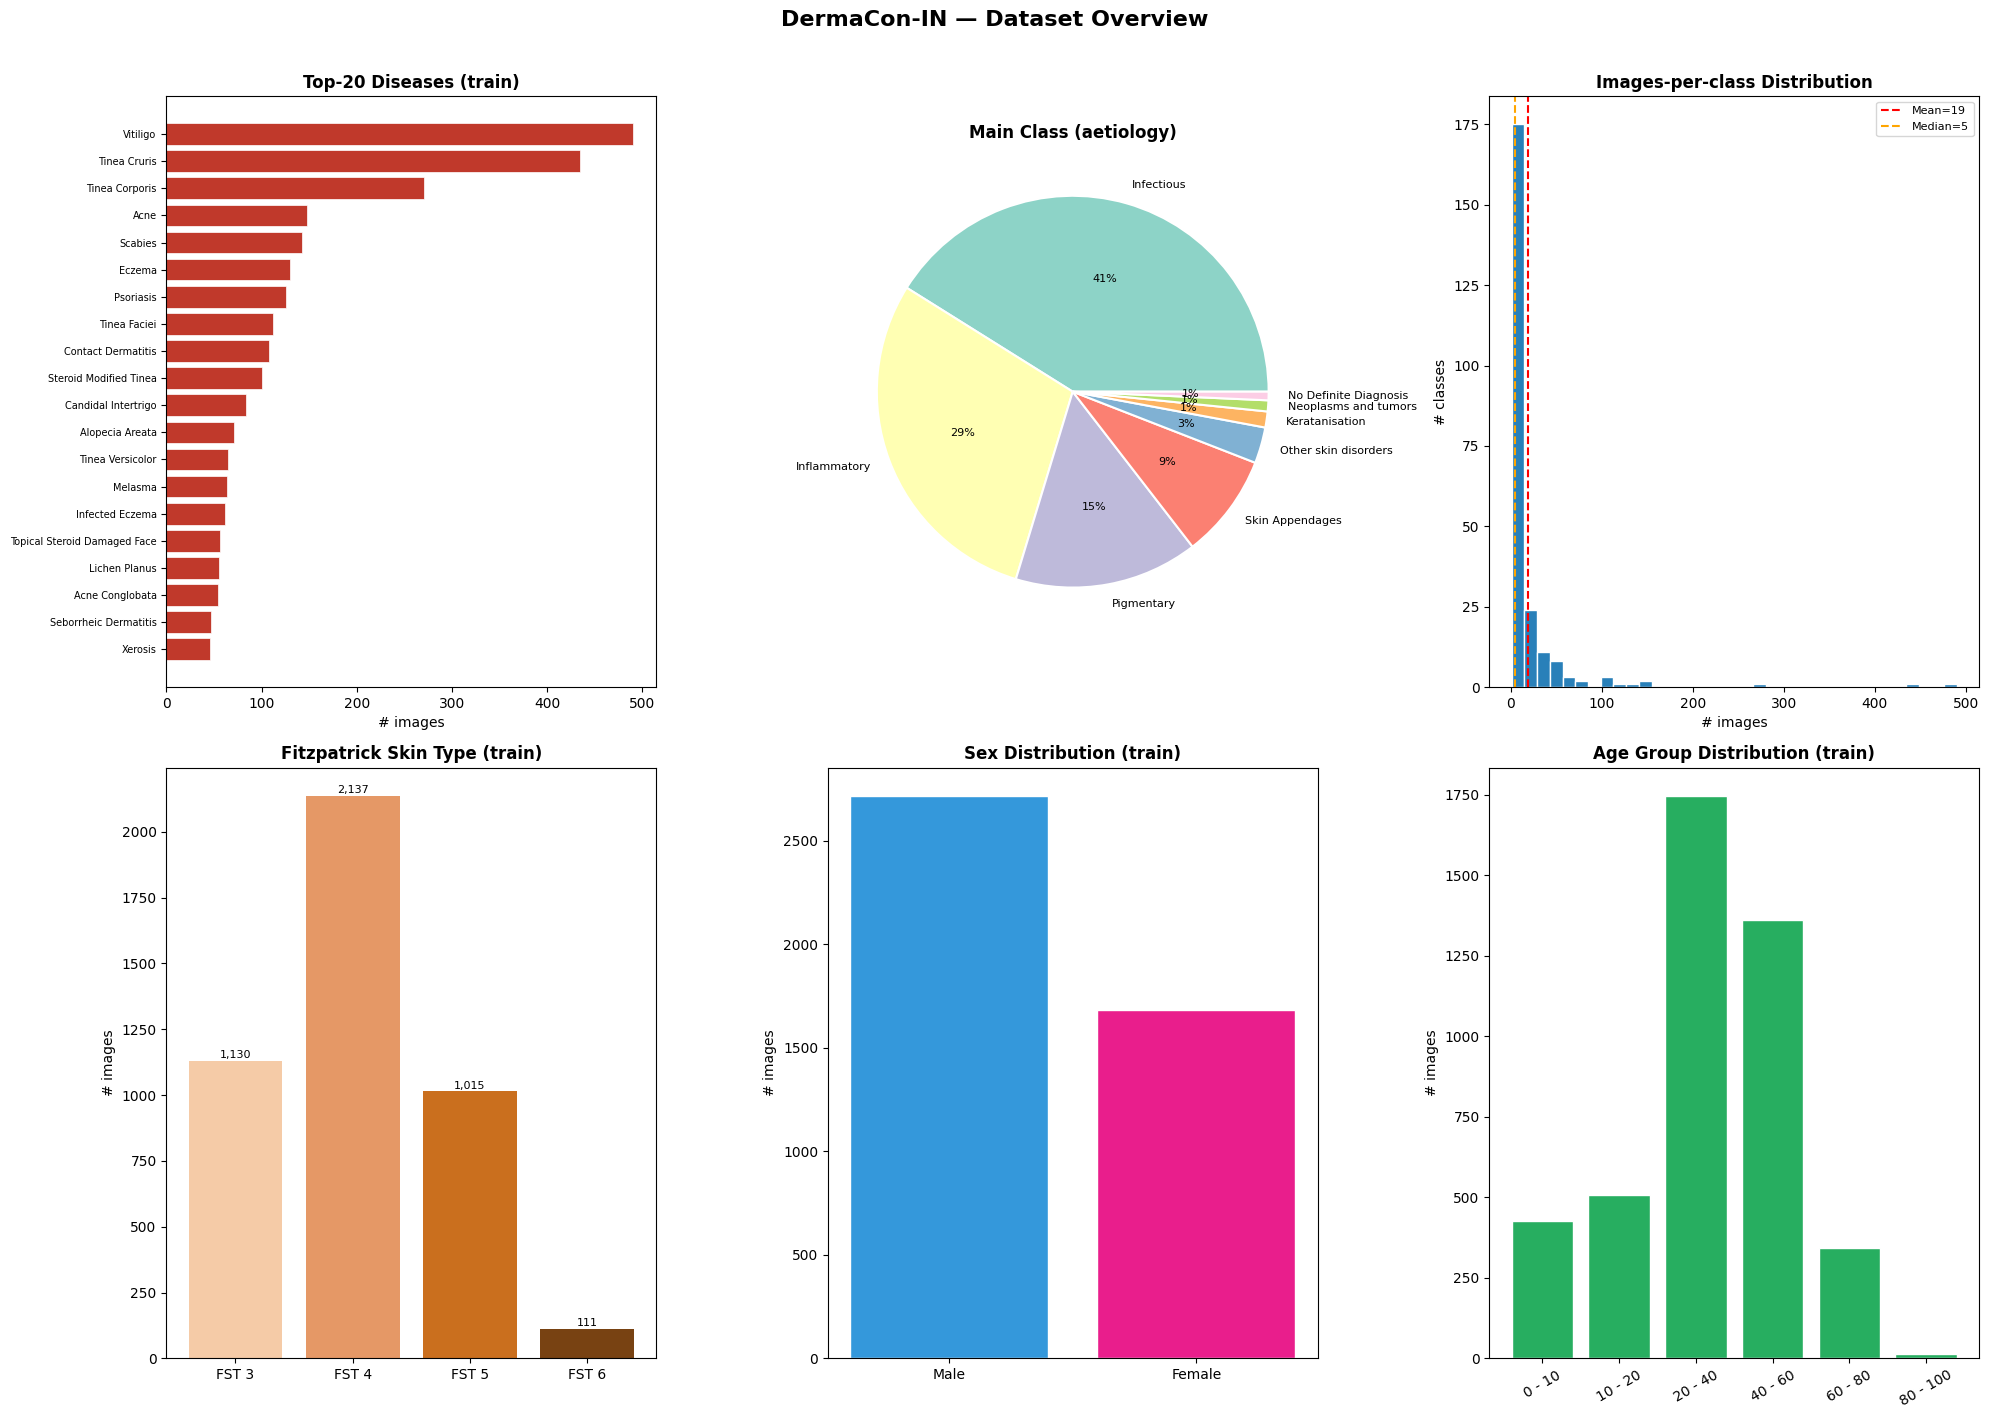

✅ EDA saved


In [ ]:
# ── EDA: visualise the dataset ────────────────────────────────────────────
train_df = full_df[full_df["_split"] == "train"].copy()

fig = plt.figure(figsize=(20, 14))
fig.suptitle("DermaCon-IN — Dataset Overview", fontsize=16, fontweight="bold", y=1.01)

# 1) Top-20 diseases (train)
ax1 = fig.add_subplot(2, 3, 1)
top20 = train_df[CFG.DISEASE_COL].value_counts().head(20)
ax1.barh(top20.index[::-1], top20.values[::-1], color="#c0392b", edgecolor="white", linewidth=0.5)
ax1.set_title("Top-20 Diseases (train)", fontweight="bold")
ax1.set_xlabel("# images"); ax1.tick_params(axis="y", labelsize=7)

# 2) Main class distribution — pie
ax2 = fig.add_subplot(2, 3, 2)
mc = train_df[CFG.MAIN_COL].value_counts()
wedge_props = {"edgecolor": "white", "linewidth": 1.5}
ax2.pie(mc.values, labels=[x.replace(" Disorders","") for x in mc.index],
        autopct="%1.0f%%", colors=plt.cm.Set3.colors,
        wedgeprops=wedge_props, textprops={"fontsize": 8})
ax2.set_title("Main Class (aetiology)", fontweight="bold")

# 3) Images-per-class histogram
ax3 = fig.add_subplot(2, 3, 3)
counts_per_class = train_df[CFG.DISEASE_COL].value_counts()
ax3.hist(counts_per_class.values, bins=35, color="#2980b9", edgecolor="white")
ax3.axvline(counts_per_class.mean(), color="red", linestyle="--",
            label=f"Mean={counts_per_class.mean():.0f}")
ax3.axvline(counts_per_class.median(), color="orange", linestyle="--",
            label=f"Median={counts_per_class.median():.0f}")
ax3.set_title("Images-per-class Distribution", fontweight="bold")
ax3.set_xlabel("# images"); ax3.set_ylabel("# classes"); ax3.legend(fontsize=8)

# 4) Fitzpatrick skin type
ax4 = fig.add_subplot(2, 3, 4)
fst = train_df[CFG.FST_COL].value_counts().sort_index()
bars = ax4.bar(fst.index, fst.values,
               color=["#f5cba7","#e59866","#ca6f1e","#784212"])
ax4.set_title("Fitzpatrick Skin Type (train)", fontweight="bold")
ax4.set_ylabel("# images")
for b in bars:
    ax4.text(b.get_x()+b.get_width()/2, b.get_height()+10,
             f"{b.get_height():,}", ha="center", fontsize=8)

# 5) Sex distribution
ax5 = fig.add_subplot(2, 3, 5)
sex = train_df[CFG.SEX_COL].value_counts()
ax5.bar(sex.index, sex.values, color=["#3498db","#e91e8c"], edgecolor="white")
ax5.set_title("Sex Distribution (train)", fontweight="bold")
ax5.set_ylabel("# images")

# 6) Age distribution
ax6 = fig.add_subplot(2, 3, 6)
age_order = ["0 - 10","10 - 20","20 - 40","40 - 60","60 - 80","80 - 100"]
age = train_df[CFG.AGE_COL].value_counts().reindex(age_order, fill_value=0)
ax6.bar(age.index, age.values, color="#27ae60", edgecolor="white")
ax6.set_title("Age Group Distribution (train)", fontweight="bold")
ax6.set_ylabel("# images"); ax6.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ EDA saved")


In [ ]:
# ── Class distribution for the 8 target classes ─────────────────────────
train_df = full_df[full_df["_split"] == "train"].copy()

counts = train_df[CFG.TARGET_COL].value_counts()
print("📊 Main class distribution (train split):")
print(f"   Classes total        : {len(counts)}")
print(f"   Max count            : {counts.max():5d}  ({counts.idxmax()})")
print(f"   Min count            : {counts.min():5d}  ({counts.idxmin()})")
print(f"   Mean                 : {counts.mean():6.1f}")
print(f"   Imbalance ratio      : {counts.max()/max(counts.min(),1):.0f}×")
print()
print(counts.to_string())
print()
print("📊 Confidence distribution (train):")
print(train_df[CFG.CONF_COL].value_counts().sort_index().to_string())


📊 Main class distribution (train split):
   Classes total        : 8
   Max count            :  1808  (Infectious Disorders)
   Min count            :    31  (No Definite Diagnosis)
   Mean                 :  549.9
   Imbalance ratio      : 58×

Main_class
Infectious Disorders         1808
Inflammatory Disorders       1285
Pigmentary Disorders          667
Skin Appendages Disorders     379
Other skin disorders          131
Keratanisation Disorders       58
Neoplasms and tumors           40
No Definite Diagnosis          31

📊 Confidence distribution (train):
Confidence
2       1
3      33
4     162
5    4203


**Stage 3 — Validation Split Generation**

Since there is **no val.csv**, we carve 15% of `train.csv` into a validation set using `StratifiedGroupKFold` with `Subject_ID` as the group key — ensuring **no patient leaks between train and val**.


In [ ]:
def make_val_split(df: pd.DataFrame, val_frac: float = CFG.VAL_FRAC) -> pd.DataFrame:
    """
    Carve a stratified, patient-disjoint val set from the training rows.
    Stratified on TARGET_COL (Main_class, 8 classes).
    """
    train_mask = df["_split"] == "train"
    train_rows = df[train_mask].copy()

    groups = train_rows[CFG.SUBJECT_COL]
    labels = train_rows[f"{CFG.TARGET_COL}_enc"]   # ← stratify on 8-class target

    n_splits = max(2, int(round(1 / val_frac)))
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

    for train_idx, val_idx in sgkf.split(train_rows, labels, groups):
        break

    val_indices = train_rows.iloc[val_idx].index
    df.loc[val_indices, "_split"] = "val"

    counts = df["_split"].value_counts()
    print("✅ Splits after carving val:")
    print(f"   Train : {counts.get('train', 0):,}")
    print(f"   Val   : {counts.get('val',   0):,}")
    print(f"   Test  : {counts.get('test',  0):,}")

    tr_subs  = set(df[df["_split"]=="train"][CFG.SUBJECT_COL])
    val_subs = set(df[df["_split"]=="val"]  [CFG.SUBJECT_COL])
    te_subs  = set(df[df["_split"]=="test"] [CFG.SUBJECT_COL])
    print(f"\n   Patient overlap train↔val  : {len(tr_subs & val_subs)}")
    print(f"   Patient overlap train↔test : {len(tr_subs & te_subs)}")
    print(f"   Patient overlap val↔test   : {len(val_subs & te_subs)}")
    return df

full_df = make_val_split(full_df)


✅ Splits after carving val:
   Train : 3,799
   Val   : 600
   Test  : 1,051

   Patient overlap train↔val  : 0
   Patient overlap train↔test : 0
   Patient overlap val↔test   : 0


**Stage 4 — Augmentation Pipeline**

Tuned for **Indian clinical photography** (Fitzpatrick III–VI, Monk V–IX):
- `CLAHE` + `HueSaturationValue` — luminance normalisation critical for darker skin tones
- Heavy geometric + colour augmentation to compensate for the **112 classes with < 5 images**
- `CoarseDropout` / `GridDropout` — simulate hair, clothing occlusion common in clinical photos


In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def build_transforms(split: str) -> A.Compose:
    if split == "train":
        return A.Compose([
            # Geometric
            A.Resize(CFG.IMG_SIZE + 32, CFG.IMG_SIZE + 32, interpolation=3),
            A.RandomCrop(CFG.IMG_SIZE, CFG.IMG_SIZE),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.10),
            A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.10,
                               rotate_limit=20, border_mode=0, p=0.65),
            A.Perspective(scale=(0.02, 0.06), p=0.20),

            # Photometric — skin-tone invariance
            A.OneOf([
                A.RandomBrightnessContrast(brightness_limit=0.35,
                                           contrast_limit=0.35, p=1),
                A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=1),
                A.HueSaturationValue(hue_shift_limit=10,
                                     sat_shift_limit=40,
                                     val_shift_limit=30, p=1),
            ], p=0.85),
            A.RandomGamma(gamma_limit=(75, 130), p=0.30),
            A.RGBShift(r_shift_limit=15, g_shift_limit=10,
                       b_shift_limit=15, p=0.25),
            A.ToGray(p=0.05),   # rare; forces texture over colour

            # Texture / noise (simulate varying phone/clinic cameras)
            A.OneOf([
                A.GaussianBlur(blur_limit=(3, 5), p=1),
                A.MotionBlur(blur_limit=5, p=1),
                A.MedianBlur(blur_limit=3, p=1),
                A.Sharpen(alpha=(0.2, 0.5), p=1),
            ], p=0.35),
            A.GaussNoise(var_limit=(10, 60), p=0.30),
            A.ImageCompression(quality_lower=70, quality_upper=100, p=0.20),

            # Occlusion (hair, clothing, accessories)
            A.CoarseDropout(max_holes=10, max_height=32, max_width=32,
                            min_holes=1, fill_value=0, p=0.30),
            A.GridDropout(ratio=0.30, p=0.15),

            A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
            ToTensorV2(),
        ])
    else:
        return A.Compose([
            A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE, interpolation=3),
            A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
            ToTensorV2(),
        ])

print("✅ Augmentation pipeline ready")


✅ Augmentation pipeline ready


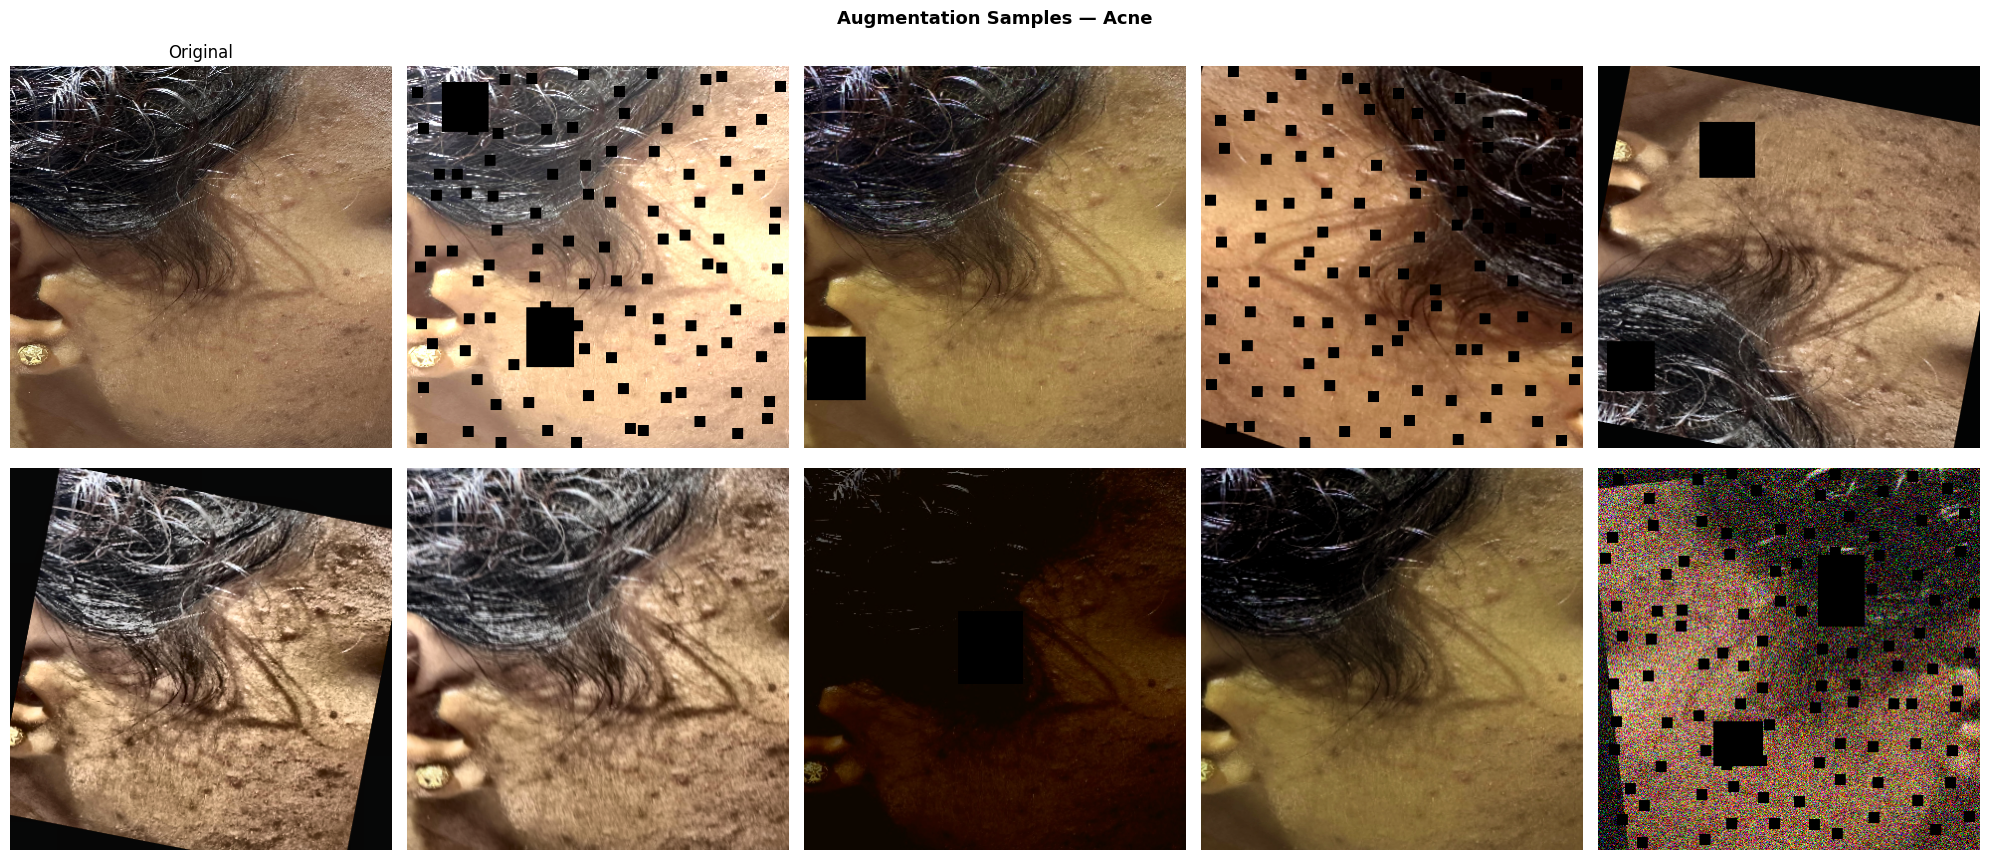

In [ ]:
# ── Preview augmentations on a real training image ────────────────────────
sample_row = full_df[full_df["_split"] == "train"].iloc[0]
img_path   = img_lookup.get(sample_row[CFG.IMAGE_COL])

if img_path:
    orig = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    orig = cv2.resize(orig, (CFG.IMG_SIZE, CFG.IMG_SIZE))

    train_t = build_transforms("train")
    fig, axes = plt.subplots(2, 5, figsize=(20, 9))
    fig.suptitle(f"Augmentation Samples — {sample_row[CFG.DISEASE_COL]}",
                 fontsize=13, fontweight="bold")

    axes[0, 0].imshow(orig); axes[0, 0].set_title("Original"); axes[0, 0].axis("off")

    for ax in axes.flat[1:]:
        aug = train_t(image=orig.copy())["image"]
        img_show = aug.permute(1,2,0).numpy()
        img_show = img_show * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
        img_show = np.clip(img_show, 0, 1)
        ax.imshow(img_show); ax.axis("off")

    plt.tight_layout()
    plt.savefig(CFG.OUTPUT_DIR / "augmentation_preview.png", dpi=130, bbox_inches="tight")
    plt.show()
else:
    print("⚠️  Image not found in lookup — check CFG.IMG_DIRS paths")


**Stage 5–6 — Dataset Class & DataLoaders**

Key features:
- **Dual-subfolder lookup** — searches `dataset_0` then `dataset_1` automatically
- **Metadata features** — the 49 body-part + 47 descriptor one-hot vectors are passed to the model as auxiliary tabular inputs alongside the image
- **WeightedRandomSampler** — inverse-frequency weights so rare classes aren't starved


In [ ]:
# Identify tabular feature columns
BODY_COLS = [c for c in full_df.columns if c.startswith(CFG.BODY_PART_PREFIX)]
DESC_COLS = [c for c in full_df.columns if c.startswith(CFG.DESCRIPTOR_PREFIX)]
META_FEAT_COLS = BODY_COLS + DESC_COLS   # 96 binary features total

print(f"Tabular metadata features: {len(META_FEAT_COLS)}")
print(f"  Body-part one-hots : {len(BODY_COLS)}")
print(f"  Descriptor one-hots: {len(DESC_COLS)}")
CFG.NUM_META_FEATS = len(META_FEAT_COLS)


Tabular metadata features: 96
  Body-part one-hots : 49
  Descriptor one-hots: 47


In [ ]:
class DermaConDataset(Dataset):
    """
    DermaCon-IN Dataset — 8-class Main_class prediction.

    Returns:
        image  : (3, H, W) float tensor
        meta   : (96,) float tensor of body-part + descriptor one-hots
        labels : dict with single key 'target' (encoded Main_class)
    """
    def __init__(self, df: pd.DataFrame, split: str,
                 img_lookup: dict, meta_cols: list):
        self.df         = df[df["_split"] == split].reset_index(drop=True)
        self.transform  = build_transforms(split)
        self.img_lookup = img_lookup
        self.meta_cols  = meta_cols

    def __len__(self):
        return len(self.df)

    def _load_image(self, name: str) -> np.ndarray:
        path = self.img_lookup.get(name)
        if path:
            img = cv2.imread(path)
            if img is not None:
                return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        return np.zeros((CFG.IMG_SIZE, CFG.IMG_SIZE, 3), dtype=np.uint8)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = self._load_image(str(row[CFG.IMAGE_COL]))
        image = self.transform(image=image)["image"]

        meta_vec = torch.tensor(
            row[self.meta_cols].values.astype(np.float32),
            dtype=torch.float32
        )

        labels = {
            "target": torch.tensor(int(row[f"{CFG.TARGET_COL}_enc"]), dtype=torch.long),
        }
        return image, meta_vec, labels


In [ ]:
def make_weighted_sampler(dataset: DermaConDataset) -> WeightedRandomSampler:
    """Inverse-frequency sampler on the 8 target classes."""
    enc_col      = f"{CFG.TARGET_COL}_enc"
    labels       = dataset.df[enc_col].values
    class_counts = np.bincount(labels, minlength=CFG.NUM_CLASSES).astype(float)
    class_weights = np.where(class_counts > 0, 1.0 / (class_counts + 1), 0.0)
    sample_w     = class_weights[labels]
    return WeightedRandomSampler(
        torch.from_numpy(sample_w).float(),
        num_samples=len(sample_w),
        replacement=True
    )


def build_loaders(full_df: pd.DataFrame):
    train_ds = DermaConDataset(full_df, "train", img_lookup, META_FEAT_COLS)
    val_ds   = DermaConDataset(full_df, "val",   img_lookup, META_FEAT_COLS)
    test_ds  = DermaConDataset(full_df, "test",  img_lookup, META_FEAT_COLS)

    sampler  = make_weighted_sampler(train_ds)

    train_dl = DataLoader(
        train_ds, batch_size=CFG.BATCH_SIZE, sampler=sampler,
        num_workers=CFG.NUM_WORKERS, pin_memory=True, drop_last=True
    )
    val_dl = DataLoader(
        val_ds, batch_size=CFG.BATCH_SIZE * 2, shuffle=False,
        num_workers=CFG.NUM_WORKERS, pin_memory=True
    )
    test_dl = DataLoader(
        test_ds, batch_size=CFG.BATCH_SIZE * 2, shuffle=False,
        num_workers=CFG.NUM_WORKERS, pin_memory=True
    )
    return train_dl, val_dl, test_dl


train_dl, val_dl, test_dl = build_loaders(full_df)

print("✅ DataLoaders ready")
print(f"   Train : {len(train_dl.dataset):,} samples  ({len(train_dl)} batches)")
print(f"   Val   : {len(val_dl.dataset):,}  samples  ({len(val_dl)} batches)")
print(f"   Test  : {len(test_dl.dataset):,}  samples  ({len(test_dl)} batches)")

imgs, meta, labels = next(iter(train_dl))
print(f"\nBatch shapes:")
print(f"   images : {tuple(imgs.shape)}")
print(f"   meta   : {tuple(meta.shape)}")
print(f"   target : {tuple(labels['target'].shape)}  (8-class)")


✅ DataLoaders ready
   Train : 3,799 samples  (237 batches)
   Val   : 600  samples  (19 batches)
   Test  : 1,051  samples  (33 batches)

Batch shapes:
   images : (16, 3, 384, 384)
   meta   : (16, 96)
   target : (16,)  (8-class)


**Stage 7 — Model Architecture (8-class)**

```
EfficientNetV2-L (ImageNet pretrained, 384px)
         │
         ▼ feature vector (feat_dim)
  Linear(feat_dim → 1024) + BN + GELU + Dropout(0.4)
         │
         +── metadata (96-dim) → Linear(96→128) → GELU
         │
    cat → (1152-dim)
         │
         ▼
    head_target  (8 Main_class outputs)
```

Single classification head — simpler and stronger for 8 classes.


In [ ]:
class MetadataEncoder(nn.Module):
    def __init__(self, in_dim: int = 96, out_dim: int = 128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.30),
            nn.Linear(256, out_dim),
            nn.GELU(),
        )
    def forward(self, x):
        return self.net(x)


class DermaMainClassModel(nn.Module):
    """
    EfficientNetV2-L + clinical metadata fusion.
    Single head for 8-class Main_class prediction.
    """
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model(
            CFG.BACKBONE,
            pretrained=CFG.PRETRAINED,
            num_classes=0,
            drop_rate=CFG.DROP_RATE,
            drop_path_rate=CFG.DROP_PATH_RATE,
        )
        feat_dim = self.backbone.num_features

        self.img_proj = nn.Sequential(
            nn.Linear(feat_dim, 1024),
            nn.BatchNorm1d(1024),
            nn.GELU(),
            nn.Dropout(0.40),
        )
        self.meta_enc = MetadataEncoder(in_dim=CFG.NUM_META_FEATS, out_dim=128)

        fused_dim = 1024 + 128  # 1152
        self.head_target = nn.Linear(fused_dim, CFG.NUM_CLASSES)

    def freeze_backbone(self, freeze: bool = True):
        for p in self.backbone.parameters():
            p.requires_grad = not freeze
        print(f"   Backbone {'FROZEN' if freeze else 'UNFROZEN'}")

    def forward(self, image, meta):
        vis  = self.backbone(image)
        vis  = self.img_proj(vis)
        met  = self.meta_enc(meta)
        feat = torch.cat([vis, met], dim=1)
        return {"target": self.head_target(feat)}


def build_model() -> DermaMainClassModel:
    model  = DermaMainClassModel().to(CFG.DEVICE)
    total  = sum(p.numel() for p in model.parameters()) / 1e6
    train_ = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    print(f"✅ Model built: {CFG.BACKBONE}  (8-class)")
    print(f"   Total params    : {total:.1f}M")
    print(f"   Trainable params: {train_:.1f}M")
    return model

model = build_model()


model.safetensors:   0%|          | 0.00/476M [00:00<?, ?B/s]

✅ Model built: tf_efficientnetv2_l  (8-class)
   Total params    : 118.6M
   Trainable params: 118.6M


**Stage 8 — Loss Functions (8-class)**

- **Focal Loss (γ=2) + Label Smoothing (0.05)**: handles the ~58× imbalance (Infectious vs No Definite Diagnosis)
- **MixUp (α=0.3)**: gentler mixing for fewer classes
- Single loss term — no hierarchical weighting needed


In [ ]:
# ── MixUp ─────────────────────────────────────────────────────────────────
def mixup_data(x, meta, y, alpha=CFG.MIXUP_ALPHA):
    if alpha <= 0:
        return x, meta, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    return (lam * x + (1-lam) * x[idx],
            lam * meta + (1-lam) * meta[idx],
            y, y[idx], lam)

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1-lam) * criterion(pred, y_b)


# ── Focal Loss ────────────────────────────────────────────────────────────
class FocalLoss(nn.Module):
    def __init__(self, gamma: float = CFG.FOCAL_GAMMA,
                 smoothing: float = CFG.LABEL_SMOOTH):
        super().__init__()
        self.gamma     = gamma
        self.smoothing = smoothing

    def forward(self, logits, targets):
        n = logits.size(-1)
        with torch.no_grad():
            smooth = torch.full_like(logits, self.smoothing / (n - 1))
            smooth.scatter_(-1, targets.unsqueeze(-1), 1.0 - self.smoothing)
        log_p  = F.log_softmax(logits, dim=-1)
        focal  = (1 - log_p.exp()) ** self.gamma * log_p
        return -(smooth * focal).sum(dim=-1).mean()


# ── Single-task loss ──────────────────────────────────────────────────────
class MainClassLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.focal = FocalLoss()

    def forward(self, preds: dict, labels: dict,
                lam: float = 1.0, y_b=None) -> dict:
        if y_b is not None and lam < 1.0:
            loss = mixup_criterion(self.focal, preds["target"],
                                   labels["target"], y_b, lam)
        else:
            loss = self.focal(preds["target"], labels["target"])
        return {"total": loss}


criterion = MainClassLoss().to(CFG.DEVICE)
print(f"✅ Loss ready  (single-task focal, γ={CFG.FOCAL_GAMMA}, smooth={CFG.LABEL_SMOOTH})")


✅ Loss ready  (single-task focal, γ=2.0, smooth=0.05)


**Stage 9 — Two-Stage Training**

In [ ]:
def build_optimizer(model, lr):
    return create_optimizer_v2(
        model, opt="adamw", lr=lr,
        weight_decay=CFG.WEIGHT_DECAY,
        filter_bias_and_bn=True
    )

def build_scheduler(optimizer, n_epochs, n_warmup):
    scheduler, _ = create_scheduler_v2(
        optimizer, sched="cosine",
        num_epochs=n_epochs,
        warmup_epochs=n_warmup,
        min_lr=CFG.LR_MIN
    )
    return scheduler

print("✅ Optimizer / scheduler helpers ready")


✅ Optimizer / scheduler helpers ready


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion,
                    scaler, scheduler, epoch: int) -> dict:
    model.train()
    optimizer.zero_grad()
    running     = defaultdict(float)
    correct = n = 0
    accumulated = False

    for step, (imgs, meta, labels) in enumerate(loader):
        imgs   = imgs.to(CFG.DEVICE, non_blocking=True)
        meta   = meta.to(CFG.DEVICE, non_blocking=True)
        labels = {k: v.to(CFG.DEVICE, non_blocking=True) for k,v in labels.items()}

        if CFG.MIXUP_ALPHA > 0:
            imgs, meta, y_a, y_b, lam = mixup_data(imgs, meta, labels["target"])
        else:
            y_a, y_b, lam = labels["target"], None, 1.0
        labels["target"] = y_a

        with autocast("cuda", enabled=CFG.FP16):
            preds  = model(imgs, meta)
            losses = criterion(preds, labels, lam=lam,
                               y_b=y_b if lam < 1.0 else None)

        scaler.scale(losses["total"] / CFG.ACCUM_STEPS).backward()
        accumulated = True

        if (step + 1) % CFG.ACCUM_STEPS == 0:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            accumulated = False

        for k, v in losses.items():
            running[k] += v.item()

        with torch.no_grad():
            correct += (preds["target"].argmax(1) == y_a).sum().item()
            n       += y_a.size(0)

    # Flush any remaining accumulated gradients at end of epoch
    if accumulated:
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad()

    if scheduler:
        scheduler.step(epoch)

    return {k: v/len(loader) for k,v in running.items()} | {"acc": correct/n}


@torch.no_grad()
def validate(model, loader, criterion) -> dict:
    model.eval()
    running = defaultdict(float)
    all_preds, all_logits, all_labels = [], [], []

    for imgs, meta, labels in loader:
        imgs   = imgs.to(CFG.DEVICE, non_blocking=True)
        meta   = meta.to(CFG.DEVICE, non_blocking=True)
        labels = {k: v.to(CFG.DEVICE, non_blocking=True) for k,v in labels.items()}

        with autocast("cuda", enabled=CFG.FP16):
            preds  = model(imgs, meta)
            losses = criterion(preds, labels)

        for k, v in losses.items():
            running[k] += v.item()

        all_logits.append(preds["target"].cpu())
        all_preds.append(preds["target"].argmax(1).cpu())
        all_labels.append(labels["target"].cpu())

    all_logits = torch.cat(all_logits).numpy()
    all_preds  = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()

    top1 = (all_preds == all_labels).mean()
    # top3/top5 capped at NUM_CLASSES (8)
    k3   = min(3, CFG.NUM_CLASSES)
    k5   = min(5, CFG.NUM_CLASSES)
    top3 = top_k_accuracy_score(all_labels, all_logits, k=k3,
                                 labels=list(range(CFG.NUM_CLASSES)))
    top5 = top_k_accuracy_score(all_labels, all_logits, k=k5,
                                 labels=list(range(CFG.NUM_CLASSES)))
    bal  = balanced_accuracy_score(all_labels, all_preds)

    return {k: v/len(loader) for k,v in running.items()} |            {"top1": top1, "top3": top3, "top5": top5, "bal_acc": bal}

print("✅ Train / validate functions ready")


✅ Train / validate functions ready


In [ ]:
#To force a retrain uncomment these
# ── Force retrain — run this cell then re-run the training cell ───────────
# (CFG.OUTPUT_DIR / "training_complete.flag").unlink(missing_ok=True)
# (CFG.OUTPUT_DIR / "resume_checkpoint_8class.pth").unlink(missing_ok=True)
# (CFG.OUTPUT_DIR / "best_model_8class.pth").unlink(missing_ok=True)
# print("🗑️  Cleared — training will restart from scratch")

In [ ]:
# ── History tracker ───────────────────────────────────────────────────────
history    = defaultdict(list)
best_top1  = 0.0
no_improve = 0
best_path   = CFG.OUTPUT_DIR / "best_model_8class.pth"
resume_path = CFG.OUTPUT_DIR / "resume_checkpoint_8class.pth"
done_flag   = CFG.OUTPUT_DIR / "training_complete.flag"  # ← ADD THIS

model  = build_model()
scaler = GradScaler("cuda", enabled=CFG.FP16)

# ── Skip training if already done ─────────────────────────────────────────
if done_flag.exists() and best_path.exists():                # ← ADD THIS
    print("✅ Training already complete — loading best model")  #
    ckpt = torch.load(best_path, map_location=CFG.DEVICE,   #
                      weights_only=False)                    #
    model.load_state_dict(ckpt["state_dict"])               #
    best_top1 = ckpt["top1"]                               #
    history   = defaultdict(list, ckpt.get("history", {})) #
    print(f"   Best val Top-1: {best_top1*100:.2f}%")      #
else:                                                        # ← WRAP REST IN else:

    # ── Resume from checkpoint if available ──────────────────────────────────
    start_stage = 1
    start_epoch = 1

    if resume_path.exists():
        print(f"🔄 Resuming from: {resume_path}")
        ckpt = torch.load(resume_path, map_location=CFG.DEVICE, weights_only=False)
        model.load_state_dict(ckpt["state_dict"])
        scaler.load_state_dict(ckpt["scaler"])
        history     = defaultdict(list, ckpt["history"])
        best_top1   = ckpt["best_top1"]
        no_improve  = ckpt["no_improve"]
        start_stage = ckpt["stage"]
        start_epoch = ckpt["epoch"] + 1
        print(f"   Stage {start_stage}, Epoch {start_epoch}  |  Best: {best_top1*100:.2f}%")
    else:
        print("🆕 Starting from scratch")

    # ══════════════════════════════════════════════════════════════
    # STAGE 1 — Freeze backbone
    # ══════════════════════════════════════════════════════════════
    if start_stage == 1:
        print("\n" + "="*60)
        print("  STAGE 1 — Frozen backbone  (warm-up heads)")
        print("="*60)

        model.freeze_backbone(True)
        optimizer = build_optimizer(model, CFG.LR)
        scheduler = build_scheduler(optimizer, CFG.FREEZE_EPOCHS, 1)

        for _ in range(start_epoch - 1):
            scheduler.step(_)

        for epoch in range(start_epoch, CFG.FREEZE_EPOCHS + 1):
            t = train_one_epoch(model, train_dl, optimizer, criterion,
                                scaler, scheduler, epoch)
            v = validate(model, val_dl, criterion)
            print(f"  [S1 E{epoch:02d}]  loss={t['total']:.4f}  acc={t['acc']:.3f}  ||  "
                  f"val top1={v['top1']:.4f}  top3={v['top3']:.4f}  bal={v['bal_acc']:.4f}")

            torch.save({"stage": 1, "epoch": epoch,
                        "state_dict": model.state_dict(),
                        "scaler": scaler.state_dict(),
                        "history": dict(history),
                        "best_top1": best_top1,
                        "no_improve": no_improve}, resume_path)

        start_epoch = 1

    # ══════════════════════════════════════════════════════════════
    # STAGE 2 — Full fine-tuning
    # ══════════════════════════════════════════════════════════════
    print("\n" + "="*60)
    print("  STAGE 2 — Full fine-tuning  (all layers, lower LR)")
    print("="*60)

    model.freeze_backbone(False)
    optimizer = build_optimizer(model, CFG.UNFREEZE_LR)
    scheduler = build_scheduler(optimizer,
                                 CFG.EPOCHS - CFG.FREEZE_EPOCHS,
                                 CFG.WARMUP_EPOCHS)

    s2_start = start_epoch if start_stage == 2 else 1
    for _ in range(s2_start - 1):
        scheduler.step(_)

    for epoch in range(CFG.FREEZE_EPOCHS + s2_start, CFG.EPOCHS + 1):
        t = train_one_epoch(model, train_dl, optimizer, criterion,
                            scaler, scheduler, epoch - CFG.FREEZE_EPOCHS)
        v = validate(model, val_dl, criterion)

        history["train_loss"].append(t["total"])
        history["train_acc"].append(t["acc"])
        history["val_top1"].append(v["top1"])
        history["val_top3"].append(v["top3"])
        history["val_bal"].append(v["bal_acc"])
        history["val_loss"].append(v["total"])

        flag = ""
        if v["top1"] > best_top1:
            best_top1  = v["top1"]
            no_improve = 0
            torch.save({"epoch": epoch,
                        "state_dict": model.state_dict(),
                        "top1": best_top1,
                        "history": dict(history),
                        "le_target":  CFG.le_target,
                        "meta_cols":  META_FEAT_COLS,
                        "num_classes": CFG.NUM_CLASSES}, best_path)
            flag = "  ✅ best"
        else:
            no_improve += 1

        print(f"  [S2 E{epoch:03d}]  loss={t['total']:.4f}  acc={t['acc']:.3f}  ||  "
              f"val top1={v['top1']:.4f}  top3={v['top3']:.4f}  "
              f"bal={v['bal_acc']:.4f}{flag}")

        torch.save({"stage": 2, "epoch": epoch - CFG.FREEZE_EPOCHS,
                    "state_dict": model.state_dict(),
                    "scaler": scaler.state_dict(),
                    "history": dict(history),
                    "best_top1": best_top1,
                    "no_improve": no_improve}, resume_path)

        if no_improve >= CFG.EARLY_STOP:
            print(f"\n⏹  Early stopping at epoch {epoch}")
            break

    # Clean up and write completion flag
    if resume_path.exists():
        resume_path.unlink()
    done_flag.touch()                                        # ← ADD THIS
    print("🗑️  Resume checkpoint deleted (training complete)")

print(f"\n🏆 Best val Top-1: {best_top1*100:.2f}%")

✅ Model built: tf_efficientnetv2_l  (8-class)
   Total params    : 118.6M
   Trainable params: 118.6M
✅ Training already complete — loading best model
   Best val Top-1: 72.83%

🏆 Best val Top-1: 72.83%


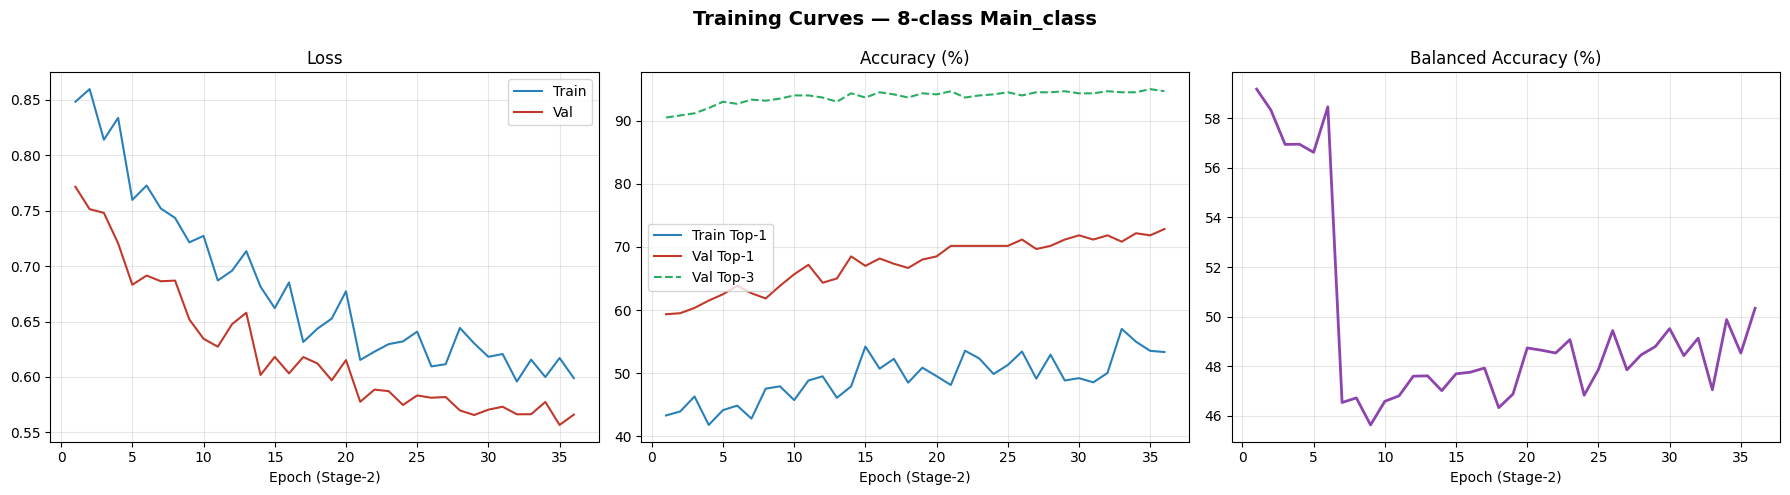

In [ ]:
# ── Training curves ───────────────────────────────────────────────────────
epochs_s2 = range(1, len(history["val_top1"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Training Curves — 8-class Main_class", fontsize=14, fontweight="bold")

axes[0].plot(epochs_s2, history["train_loss"], label="Train", color="#2980b9")
axes[0].plot(epochs_s2, history["val_loss"],   label="Val",   color="#c0392b")
axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_xlabel("Epoch (Stage-2)")

axes[1].plot(epochs_s2, [x*100 for x in history["train_acc"]],
             label="Train Top-1", color="#2980b9")
axes[1].plot(epochs_s2, [x*100 for x in history["val_top1"]],
             label="Val Top-1", color="#c0392b")
axes[1].plot(epochs_s2, [x*100 for x in history["val_top3"]],
             label="Val Top-3", color="#27ae60", linestyle="--")
axes[1].set_title("Accuracy (%)"); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_xlabel("Epoch (Stage-2)")

axes[2].plot(epochs_s2, [x*100 for x in history["val_bal"]],
             color="#8e44ad", linewidth=2)
axes[2].set_title("Balanced Accuracy (%)"); axes[2].grid(alpha=0.3)
axes[2].set_xlabel("Epoch (Stage-2)")

plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "training_curves_8class.png", dpi=150, bbox_inches="tight")
plt.show()


**Stage 10 — Test Evaluation**

In [ ]:
@torch.no_grad()
def evaluate_test(model, checkpoint_path: Path):
    print("📂 Loading best checkpoint…")
    ckpt = torch.load(checkpoint_path, map_location=CFG.DEVICE, weights_only=False)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()

    all_preds, all_logits, all_labels = [], [], []

    for imgs, meta, labels in test_dl:
        imgs = imgs.to(CFG.DEVICE, non_blocking=True)
        meta = meta.to(CFG.DEVICE, non_blocking=True)
        with autocast("cuda", enabled=CFG.FP16):
            out = model(imgs, meta)
        all_logits.append(out["target"].cpu())
        all_preds.append(out["target"].argmax(1).cpu())
        all_labels.append(labels["target"])

    all_preds  = torch.cat(all_preds).numpy()
    all_logits = torch.cat(all_logits).numpy()
    all_labels = torch.cat(all_labels).numpy()

    top1 = (all_preds == all_labels).mean()
    top3 = top_k_accuracy_score(all_labels, all_logits, k=min(3, CFG.NUM_CLASSES),
                                 labels=list(range(CFG.NUM_CLASSES)))
    bal  = balanced_accuracy_score(all_labels, all_preds)

    print("\n" + "═"*50)
    print(f"  🎯 Top-1 Accuracy   : {top1*100:.2f}%")
    print(f"  🎯 Top-3 Accuracy   : {top3*100:.2f}%")
    print(f"  ⚖️  Balanced Acc     : {bal*100:.2f}%")
    print("═"*50)

    class_names = list(CFG.le_target.classes_)
    report = classification_report(
        all_labels, all_preds,
        target_names=class_names,
        output_dict=True, zero_division=0
    )
    pd.DataFrame(report).T.to_csv(CFG.OUTPUT_DIR / "classification_report_8class.csv")
    print("\n✅ classification_report_8class.csv saved")

    return all_preds, all_logits, all_labels, {"top1":top1,"top3":top3,"bal_acc":bal}

all_preds, all_logits, all_labels, metrics = evaluate_test(model, best_path)


📂 Loading best checkpoint…

══════════════════════════════════════════════════
  🎯 Top-1 Accuracy   : 68.60%
  🎯 Top-3 Accuracy   : 93.53%
  ⚖️  Balanced Acc     : 51.52%
══════════════════════════════════════════════════

✅ classification_report_8class.csv saved


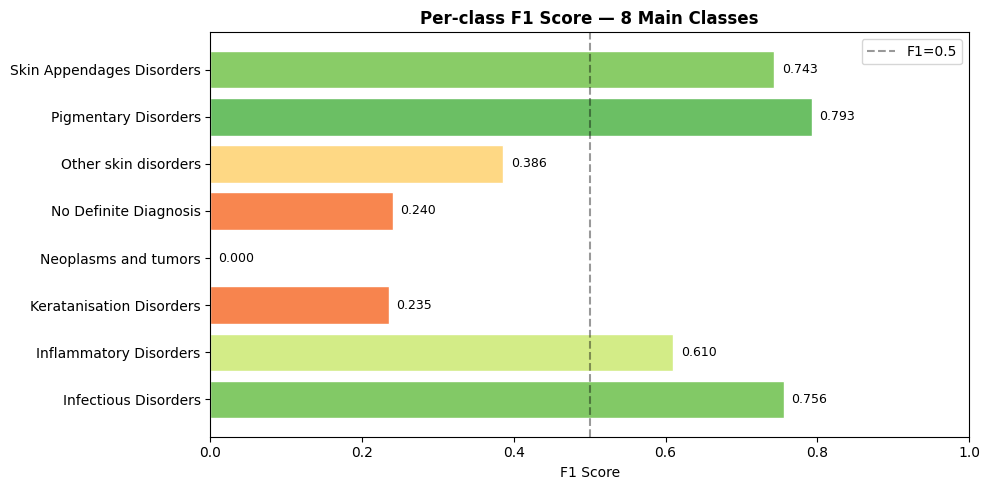

Infectious Disorders         0.755886
Inflammatory Disorders       0.610000
Keratanisation Disorders     0.235294
Neoplasms and tumors         0.000000
No Definite Diagnosis        0.240000
Other skin disorders         0.385965
Pigmentary Disorders         0.792899
Skin Appendages Disorders    0.743119


In [ ]:
# ── Per-class F1 — 8 main classes ────────────────────────────────────────
report_df  = pd.read_csv(CFG.OUTPUT_DIR / "classification_report_8class.csv", index_col=0)
class_names = list(CFG.le_target.classes_)
class_f1   = report_df.loc[class_names, "f1-score"].astype(float)

fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.RdYlGn([x for x in class_f1.values])
bars = ax.barh(class_f1.index, class_f1.values, color=colors, edgecolor="white")
ax.set_xlabel("F1 Score"); ax.set_xlim(0, 1)
ax.axvline(0.5, color="black", linestyle="--", alpha=0.4, label="F1=0.5")
ax.set_title("Per-class F1 Score — 8 Main Classes", fontweight="bold")
for bar in bars:
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f"{bar.get_width():.3f}", va="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "f1_8class.png", dpi=150, bbox_inches="tight")
plt.show()
print(class_f1.to_string())


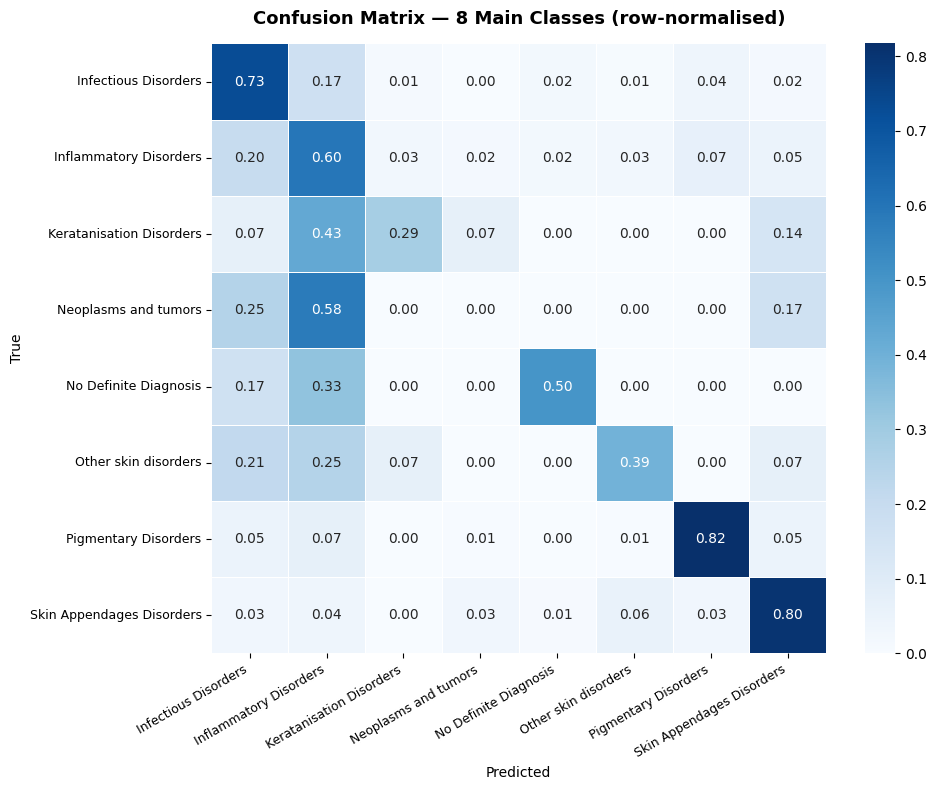

In [ ]:
# ── Full 8×8 Confusion Matrix ────────────────────────────────────────────
class_names = list(CFG.le_target.classes_)
cm = confusion_matrix(all_labels, all_preds,
                      labels=list(range(CFG.NUM_CLASSES)),
                      normalize="true")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, xticklabels=class_names, yticklabels=class_names,
            annot=True, fmt=".2f", cmap="Blues",
            linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("Confusion Matrix — 8 Main Classes (row-normalised)",
             fontsize=13, fontweight="bold", pad=14)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "confusion_matrix_8class.png", dpi=150, bbox_inches="tight")
plt.show()



📊 Per-class Accuracy (test set):
                           Accuracy  N_images
Main_class                                   
Pigmentary Disorders          81.71       164
Skin Appendages Disorders     80.20       101
Infectious Disorders          72.79       419
Inflammatory Disorders        59.61       307
No Definite Diagnosis         50.00         6
Other skin disorders          39.29        28
Keratanisation Disorders      28.57        14
Neoplasms and tumors           0.00        12


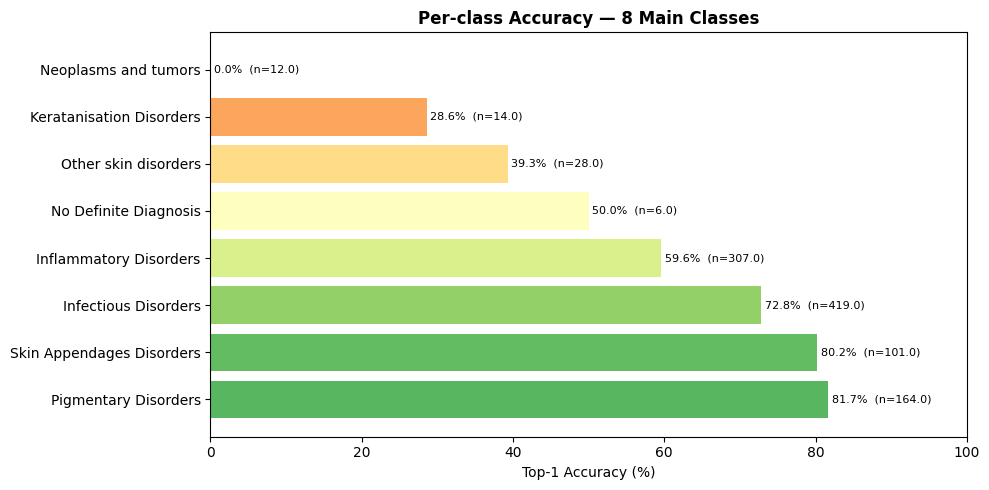

In [ ]:
# ── Per-class accuracy table ─────────────────────────────────────────────
test_df_eval = full_df[full_df["_split"]=="test"].copy()
test_df_eval["pred_enc"]    = all_preds
test_df_eval["pred_label"]  = CFG.le_target.inverse_transform(all_preds)
test_df_eval["correct"]     = (all_preds == all_labels)

print("\n📊 Per-class Accuracy (test set):")
per_class = test_df_eval.groupby(CFG.TARGET_COL)["correct"].agg(["mean","count"])
per_class.columns = ["Accuracy", "N_images"]
per_class["Accuracy"] = (per_class["Accuracy"] * 100).round(2)
per_class = per_class.sort_values("Accuracy", ascending=False)
print(per_class.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.RdYlGn([x/100 for x in per_class["Accuracy"]])
bars   = ax.barh(per_class.index, per_class["Accuracy"], color=colors)
ax.set_xlabel("Top-1 Accuracy (%)"); ax.set_xlim(0, 100)
ax.set_title("Per-class Accuracy — 8 Main Classes", fontweight="bold")
for bar, (_, row) in zip(bars, per_class.iterrows()):
    ax.text(bar.get_width()+0.5, bar.get_y()+bar.get_height()/2,
            f"{bar.get_width():.1f}%  (n={row['N_images']})",
            va="center", fontsize=8)
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "accuracy_by_class_8class.png", dpi=150, bbox_inches="tight")
plt.show()


**Stage 11 — Test-Time Augmentation (TTA ×5)**

Zero retraining cost: averages softmax probabilities over 5 geometric variants of each test image.

In [ ]:
@torch.no_grad()
def evaluate_tta(model, checkpoint_path: Path, n_tta: int = 5):
    ckpt = torch.load(checkpoint_path, map_location=CFG.DEVICE, weights_only=False)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    print(f"🔄 TTA ×{n_tta} on test set…")

    augments = [
        lambda x: torch.flip(x, dims=[3]),
        lambda x: torch.flip(x, dims=[2]),
        lambda x: torch.rot90(x, k=1, dims=[2,3]),
        lambda x: torch.rot90(x, k=3, dims=[2,3]),
    ]

    all_probs, all_labels = [], []

    for imgs, meta, labels in test_dl:
        imgs = imgs.to(CFG.DEVICE, non_blocking=True)
        meta = meta.to(CFG.DEVICE, non_blocking=True)
        probs = torch.zeros(imgs.size(0), CFG.NUM_CLASSES, device=CFG.DEVICE)

        with autocast("cuda", enabled=CFG.FP16):
            probs += F.softmax(model(imgs, meta)["target"], dim=-1)

        for aug_fn in augments[:n_tta-1]:
            with autocast("cuda", enabled=CFG.FP16):
                probs += F.softmax(model(aug_fn(imgs), meta)["target"], dim=-1)

        probs /= n_tta
        all_probs.append(probs.cpu())
        all_labels.append(labels["target"])

    all_probs  = torch.cat(all_probs).numpy()
    all_preds  = all_probs.argmax(1)
    all_labels = torch.cat(all_labels).numpy()

    top1 = (all_preds == all_labels).mean()
    top3 = top_k_accuracy_score(all_labels, all_probs, k=min(3, CFG.NUM_CLASSES),
                                 labels=list(range(CFG.NUM_CLASSES)))
    bal  = balanced_accuracy_score(all_labels, all_preds)

    print("\n" + "═"*45)
    print(f"  🎯 TTA Top-1 : {top1*100:.2f}%")
    print(f"  🎯 TTA Top-3 : {top3*100:.2f}%")
    print(f"  ⚖️  Balanced  : {bal*100:.2f}%")
    print("═"*45)
    return top1, top3, bal

tta_top1, tta_top3, tta_bal = evaluate_tta(model, best_path, n_tta=5)


🔄 TTA ×5 on test set…

═════════════════════════════════════════════
  🎯 TTA Top-1 : 68.70%
  🎯 TTA Top-3 : 94.20%
  ⚖️  Balanced  : 52.25%
═════════════════════════════════════════════


**Stage 12 — GradCAM++ Explainability**

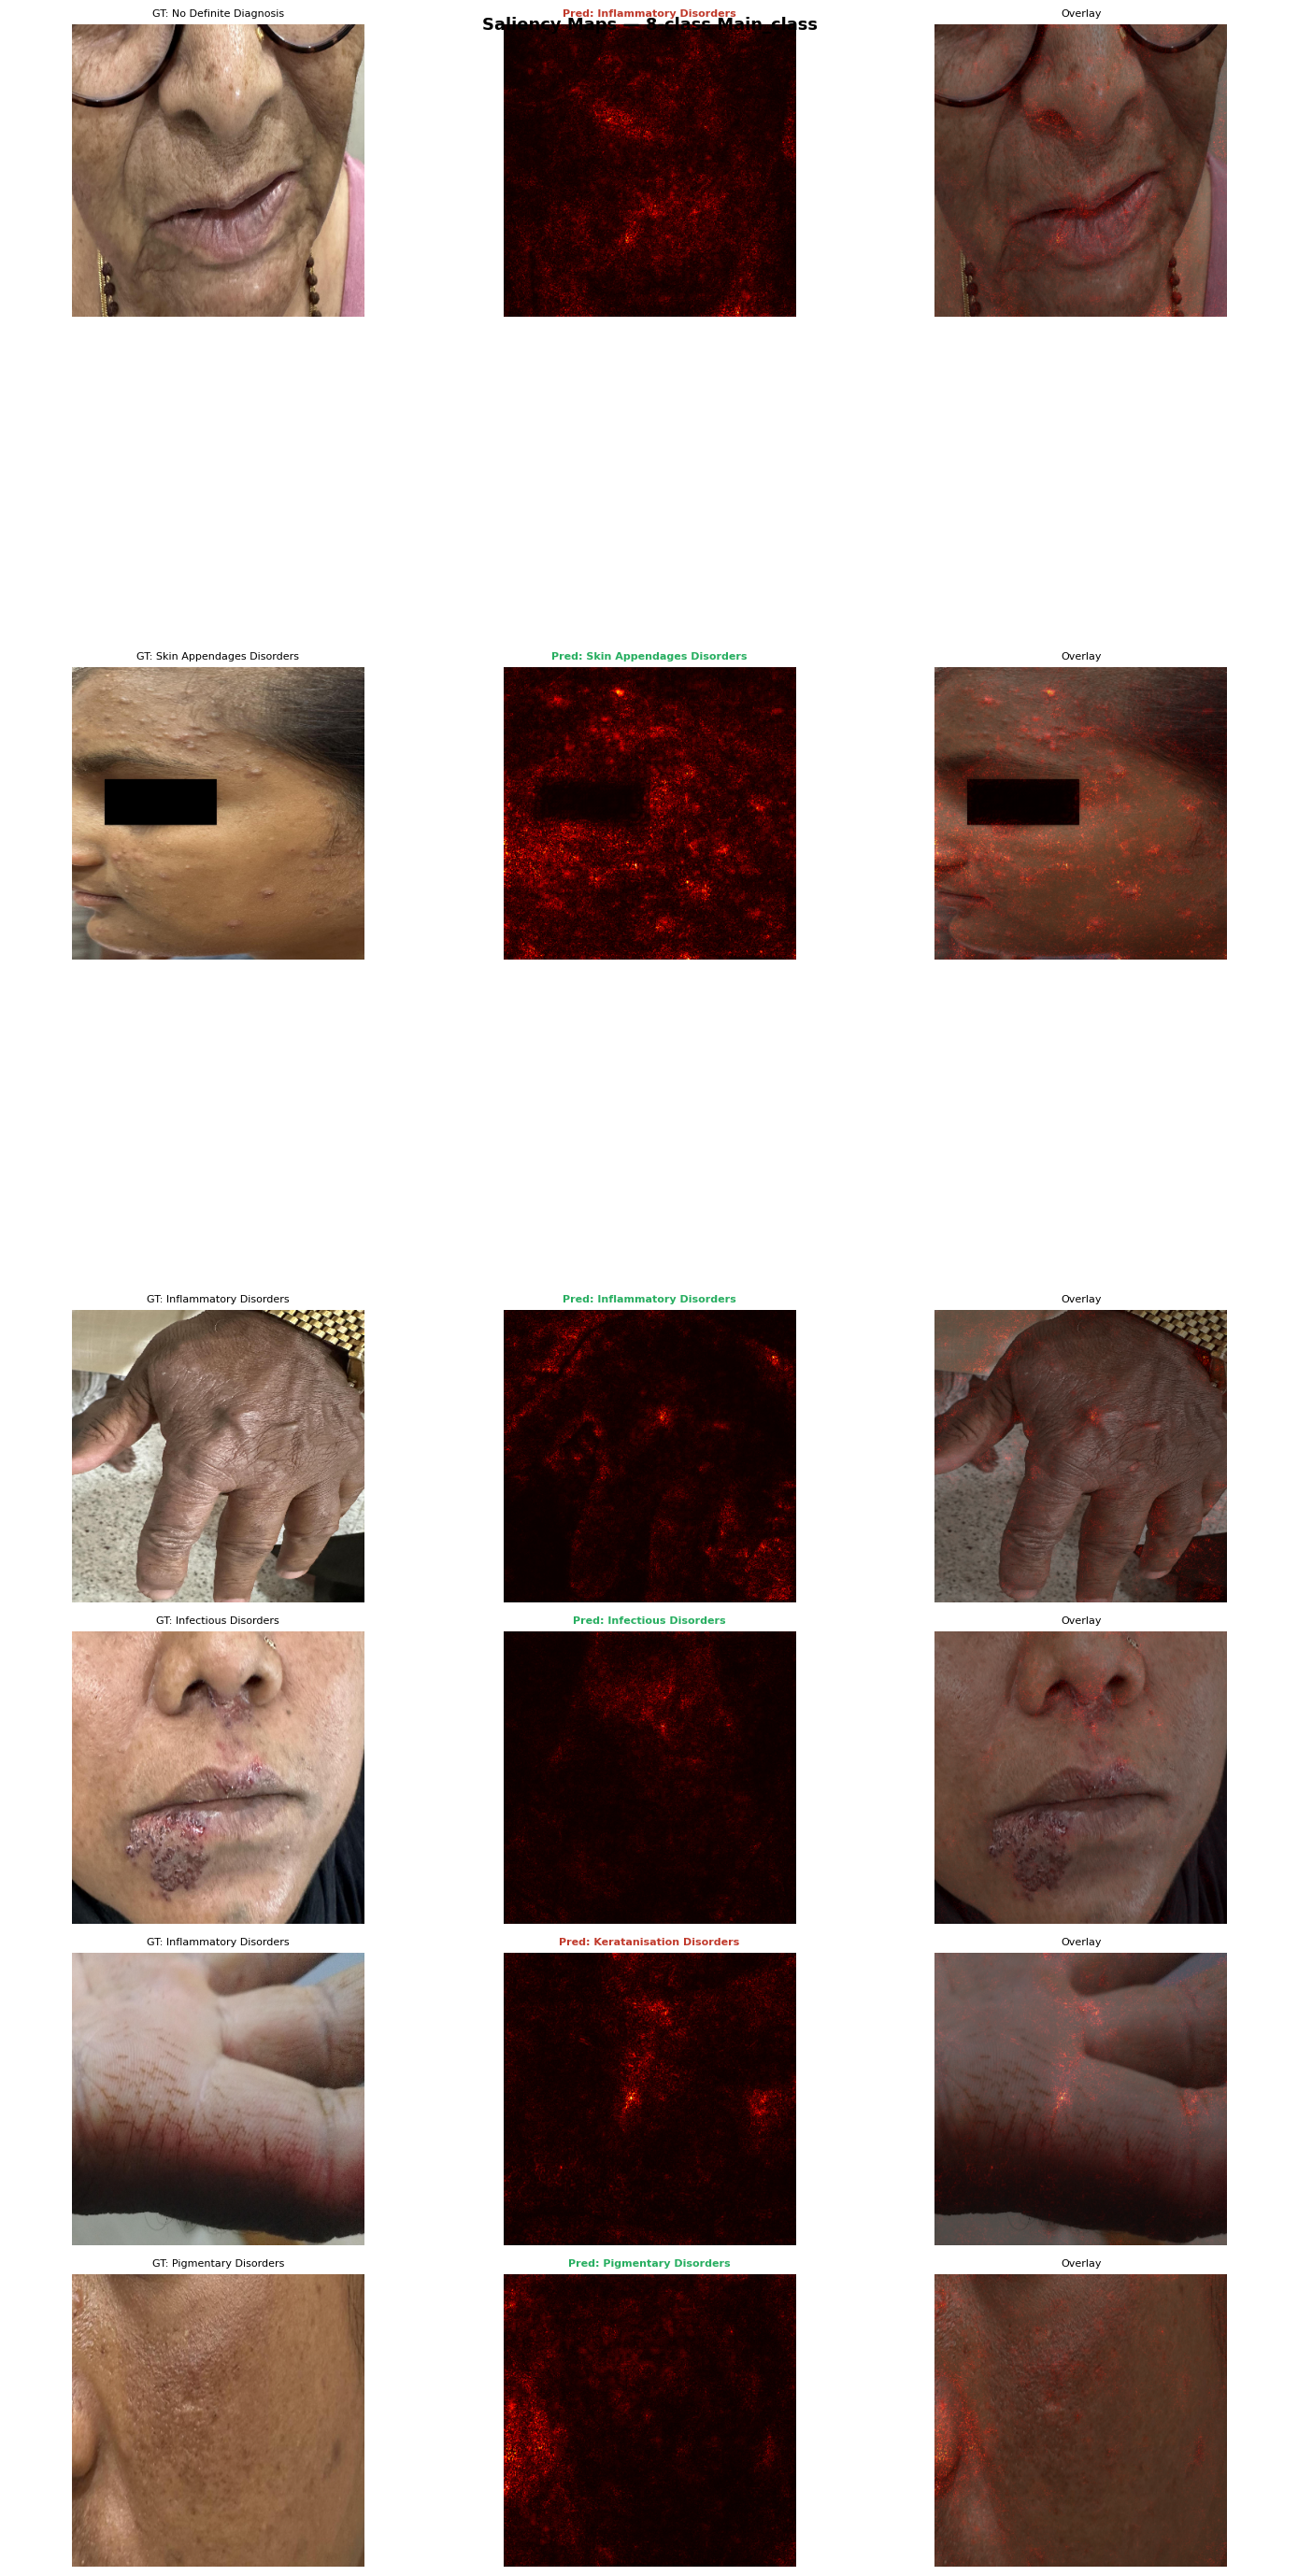

✅ Saliency maps saved


In [ ]:
def visualise_saliency(model, full_df: pd.DataFrame, n_samples: int = 8):
    """
    Vanilla gradient saliency maps — no grad-cam library needed.
    Shows which pixels most influence the prediction.
    """
    val_t   = build_transforms("val")
    samples = full_df[full_df["_split"] == "test"].sample(n_samples, random_state=SEED)

    fig, axes = plt.subplots(n_samples, 3, figsize=(14, n_samples * 3.5))
    fig.suptitle("Saliency Maps — 8-class Main_class",
                 fontsize=13, fontweight="bold")

    model.eval()

    for i, (_, row) in enumerate(samples.iterrows()):
        path = img_lookup.get(str(row[CFG.IMAGE_COL]))
        if not path:
            for ax in axes[i]: ax.axis("off")
            continue

        img_rgb = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        img_r   = cv2.resize(img_rgb, (CFG.IMG_SIZE, CFG.IMG_SIZE))

        img_t  = val_t(image=img_r.copy())["image"].unsqueeze(0).to(CFG.DEVICE)
        meta_v = torch.tensor(
            row[META_FEAT_COLS].values.astype(np.float32)
        ).unsqueeze(0).to(CFG.DEVICE)

        # ── Compute saliency ──────────────────────────────────────────────
        img_t.requires_grad_(True)

        logits   = model(img_t, meta_v)["target"]
        pred_idx = logits.argmax(1).item()
        score    = logits[0, pred_idx]
        score.backward()

        # Saliency = max absolute gradient across colour channels
        saliency = img_t.grad.data.abs()             # (1, 3, H, W)
        saliency = saliency.squeeze().max(dim=0)[0]  # (H, W)
        saliency = saliency.cpu().numpy()
        saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)

        pred_name = CFG.le_target.classes_[pred_idx]
        true_name = row[CFG.TARGET_COL]
        colour    = "#27ae60" if pred_name == true_name else "#c0392b"

        # ── Plot ──────────────────────────────────────────────────────────
        axes[i, 0].imshow(img_r)
        axes[i, 0].set_title(f"GT: {true_name}", fontsize=8)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(saliency, cmap="hot")
        axes[i, 1].set_title(f"Pred: {pred_name}", fontsize=8,
                              color=colour, fontweight="bold")
        axes[i, 1].axis("off")

        # Overlay
        saliency_rgb = plt.cm.hot(saliency)[..., :3]
        overlay      = (0.5 * img_r / 255.0 + 0.5 * saliency_rgb)
        overlay      = np.clip(overlay, 0, 1)
        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title("Overlay", fontsize=8)
        axes[i, 2].axis("off")

        img_t.requires_grad_(False)

    plt.tight_layout()
    plt.savefig(CFG.OUTPUT_DIR / "saliency_8class.png", dpi=140, bbox_inches="tight")
    plt.show()
    print("✅ Saliency maps saved")

visualise_saliency(model, full_df, n_samples=8)

**Stage 13 — Export & Inference Demo**

In [ ]:
# ── Save label maps ───────────────────────────────────────────────────────
label_maps = {
    "target_classes" : list(CFG.le_target.classes_),   # 8 main classes
    "num_classes"    : CFG.NUM_CLASSES,
    "num_meta_feats" : CFG.NUM_META_FEATS,
    "meta_feat_cols" : META_FEAT_COLS,
    "task"           : "8-class Main_class prediction",
}
with open(CFG.OUTPUT_DIR / "label_maps_8class.json", "w") as f:
    json.dump(label_maps, f, indent=2)
print("✅ label_maps_8class.json saved")


✅ label_maps_8class.json saved


In [ ]:
!pip install -q onnxscript onnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 714.8/714.8 kB 46.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 137.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 21.4 MB/s eta 0:00:00


In [ ]:
def export_onnx(checkpoint_path: Path):
    ckpt     = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    m_export = build_model()
    m_export.load_state_dict(ckpt["state_dict"])
    m_export.eval().cpu()

    dummy_img  = torch.randn(1, 3, CFG.IMG_SIZE, CFG.IMG_SIZE)
    dummy_meta = torch.zeros(1, CFG.NUM_META_FEATS)
    onnx_path  = CFG.OUTPUT_DIR / "dermaconin_8class.onnx"

    torch.onnx.export(
        m_export, (dummy_img, dummy_meta), str(onnx_path),
        input_names=["image", "metadata"],
        output_names=["main_class_logits"],
        dynamic_axes={"image": {0:"batch"}, "metadata": {0:"batch"}},
        opset_version=17, verbose=False,
    )
    print(f"✅ ONNX saved: {onnx_path}  ({onnx_path.stat().st_size/1e6:.1f} MB)")

export_onnx(best_path)


✅ Model built: tf_efficientnetv2_l  (8-class)
   Total params    : 118.6M
   Trainable params: 118.6M


W0525 15:51:52.983000 1421 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0525 15:51:53.791000 1421 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0525 15:51:53.792000 1421 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio

✅ ONNX saved: /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/skinDisease/pipeline_outputs/dermaconin_8class.onnx  (2.5 MB)


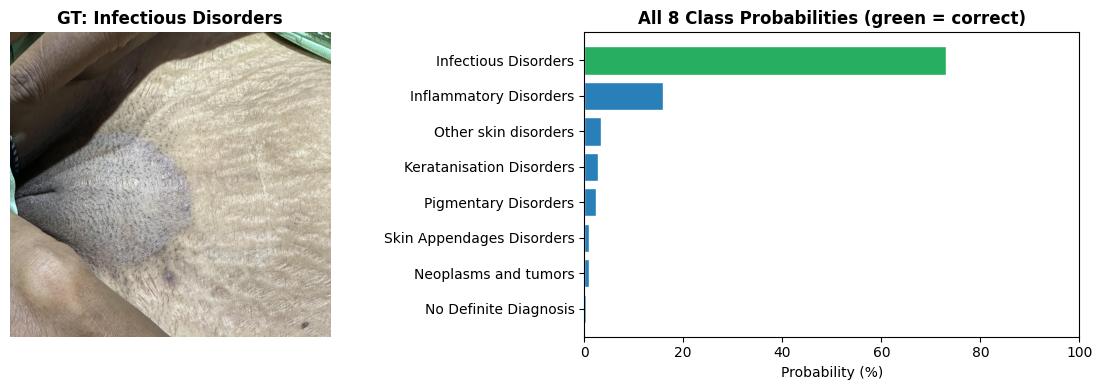


📋 Prediction:
                      rank                main_class  probability
tensor(1, device='cuda:0')      Infectious Disorders        73.11
tensor(2, device='cuda:0')    Inflammatory Disorders        15.86
tensor(6, device='cuda:0')      Other skin disorders         3.35
tensor(3, device='cuda:0')  Keratanisation Disorders         2.81
tensor(7, device='cuda:0')      Pigmentary Disorders         2.44
tensor(8, device='cuda:0') Skin Appendages Disorders         1.06
tensor(4, device='cuda:0')      Neoplasms and tumors         1.00
tensor(5, device='cuda:0')     No Definite Diagnosis         0.38


In [ ]:
@torch.no_grad()
def predict(image_name_or_path: str,
            meta_series: pd.Series = None,
            checkpoint_path: Path = best_path) -> pd.DataFrame:
    """Predict Main_class (8-class) for one image."""
    ckpt = torch.load(checkpoint_path, map_location=CFG.DEVICE, weights_only=False)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()

    path  = img_lookup.get(image_name_or_path, image_name_or_path)
    img   = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    img_t = build_transforms("val")(image=img)["image"].unsqueeze(0).to(CFG.DEVICE)

    if meta_series is not None:
        meta_v = torch.tensor(
            meta_series[META_FEAT_COLS].values.astype(np.float32)
        ).unsqueeze(0).to(CFG.DEVICE)
    else:
        meta_v = torch.zeros(1, CFG.NUM_META_FEATS).to(CFG.DEVICE)

    with autocast("cuda", enabled=CFG.FP16):
        probs = F.softmax(model(img_t, meta_v)["target"], dim=-1)[0]

    rows = [{"rank": i+1,
             "main_class": CFG.le_target.classes_[i],
             "probability": round(probs[i].item()*100, 2)}
            for i in probs.argsort(descending=True)]
    return pd.DataFrame(rows)


# ── Demo ──────────────────────────────────────────────────────────────────
test_sample = full_df[full_df["_split"]=="test"].iloc[5]
preds = predict(test_sample[CFG.IMAGE_COL], meta_series=test_sample)

path = img_lookup.get(test_sample[CFG.IMAGE_COL])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.imshow(cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB))
ax1.set_title(f"GT: {test_sample[CFG.TARGET_COL]}", fontweight="bold")
ax1.axis("off")

colors = ["#27ae60" if r["main_class"]==test_sample[CFG.TARGET_COL] else "#2980b9"
          for _,r in preds.iterrows()]
ax2.barh(preds["main_class"][::-1], preds["probability"][::-1],
         color=colors[::-1], edgecolor="white")
ax2.set_xlabel("Probability (%)"); ax2.set_xlim(0, 100)
ax2.set_title("All 8 Class Probabilities (green = correct)", fontweight="bold")
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "inference_demo_8class.png", dpi=130, bbox_inches="tight")
plt.show()
print("\n📋 Prediction:")
print(preds.to_string(index=False))


In [ ]:
# ── Copy all outputs to Drive ─────────────────────────────────────────────
import shutil

drive_out = CFG.DRIVE_ROOT / "pipeline_outputs"
drive_out.mkdir(parents=True, exist_ok=True)

for f in CFG.OUTPUT_DIR.iterdir():
    dst = drive_out / f.name
    if f.resolve() != dst.resolve():   # skip if same file
        shutil.copy(f, dst)

print(f"✅ Outputs copied to {drive_out}")
for f in sorted(drive_out.iterdir()):
    print(f"   {f.name:40s}  {f.stat().st_size/1e3:6.0f} KB")

✅ Outputs copied to /content/gdrive/MyDrive/ColabNotebooks/NEP2022PROJECTS/skinDisease/pipeline_outputs
   accuracy_by_class_8class.png                  84 KB
   augmentation_preview.png                    4166 KB
   best_model_8class.pth                     477129 KB
   classification_report_8class.csv               1 KB
   confusion_matrix_8class.png                  173 KB
   dermaconin_8class.onnx                      2525 KB
   dermaconin_8class.onnx.data               475660 KB
   eda_overview.png                             267 KB
   f1_8class.png                                 72 KB
   inference_demo_8class.png                    386 KB
   label_maps_8class.json                         4 KB
   saliency_8class.png                         5237 KB
   seed_123                                       4 KB
   seed_42                                        4 KB
   training_complete.flag                         0 KB
   training_curves_8class.png                   176 KB


In [ ]:
print("\n" + "═"*56)
print("  🏆  DermaCon-IN  ·  8-class Results Summary")
print("═"*56)
print(f"  Task             : Main_class (8 aetiology groups)")
print(f"  Backbone         : {CFG.BACKBONE}")
print(f"  Image resolution : {CFG.IMG_SIZE}×{CFG.IMG_SIZE}px")
print(f"  Metadata features: {CFG.NUM_META_FEATS}")
print()
print(f"  ── Test set (no TTA) ──────────────────────────")
print(f"     Top-1 Accuracy : {metrics['top1']*100:.2f}%")
print(f"     Top-3 Accuracy : {metrics['top3']*100:.2f}%")
print(f"     Balanced Acc   : {metrics['bal_acc']*100:.2f}%")
print()
print(f"  ── Test set (TTA ×5) ──────────────────────────")
print(f"     Top-1 Accuracy : {tta_top1*100:.2f}%")
print(f"     Top-3 Accuracy : {tta_top3*100:.2f}%")
print(f"     Balanced Acc   : {tta_bal*100:.2f}%")
print("═"*56)
print()
print("📁 Output files:")
for name in ["best_model_8class.pth", "dermaconin_8class.onnx",
             "label_maps_8class.json", "classification_report_8class.csv",
             "confusion_matrix_8class.png", "accuracy_by_class_8class.png",
             "f1_8class.png", "gradcam_8class.png",
             "training_curves_8class.png", "inference_demo_8class.png"]:
    p = CFG.OUTPUT_DIR / name
    print(f"   {'✅' if p.exists() else '⬜'}  {name}")



════════════════════════════════════════════════════════
  🏆  DermaCon-IN  ·  8-class Results Summary
════════════════════════════════════════════════════════
  Task             : Main_class (8 aetiology groups)
  Backbone         : tf_efficientnetv2_l
  Image resolution : 384×384px
  Metadata features: 96

  ── Test set (no TTA) ──────────────────────────
     Top-1 Accuracy : 68.60%
     Top-3 Accuracy : 93.53%
     Balanced Acc   : 51.52%

  ── Test set (TTA ×5) ──────────────────────────
     Top-1 Accuracy : 68.70%
     Top-3 Accuracy : 94.20%
     Balanced Acc   : 52.25%
════════════════════════════════════════════════════════

📁 Output files:
   ✅  best_model_8class.pth
   ✅  dermaconin_8class.onnx
   ✅  label_maps_8class.json
   ✅  classification_report_8class.csv
   ✅  confusion_matrix_8class.png
   ✅  accuracy_by_class_8class.png
   ✅  f1_8class.png
   ⬜  gradcam_8class.png
   ✅  training_curves_8class.png
   ✅  inference_demo_8class.png


---
**Publication Stage A — Multi-Seed Evaluation (3 seeds → mean ± std)**

Runs the full training pipeline 3 times with different random seeds.  
Reports mean ± std for all metrics — required for any ML paper.

>  **Runtime:** ~3× training time. Run overnight or use Colab Pro.  
> Each seed saves its own checkpoint so runs are resumable independently.


In [ ]:
# ── Reduce batch size for multi-seed runs to save memory ─────────────────
CFG.BATCH_SIZE  = 8    # was 16 — halves GPU memory per forward pass
CFG.ACCUM_STEPS = 8    # was 4  — keeps effective batch = 64

import gc, time

def safe_save(obj, path: Path, retries: int = 3):
    """Save with retry — handles Google Drive FUSE directory caching lag."""
    path.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(retries):
        try:
            torch.save(obj, str(path))
            return
        except RuntimeError as e:
            if attempt < retries - 1:
                print(f"    ⚠️  Save failed (attempt {attempt+1}) — retrying in 2s...")
                time.sleep(2)
            else:
                raise e


def run_single_seed(seed: int, full_df: pd.DataFrame) -> dict:
    """
    Full train + test cycle for one seed.
    Saves a resume checkpoint after every epoch.
    If Colab disconnects mid-seed, re-running resumes from last saved epoch.
    Returns dict of test metrics.
    """
    seed_everything(seed)

    seed_out = CFG.OUTPUT_DIR / f"seed_{seed}"
    seed_out.mkdir(parents=True, exist_ok=True)
    time.sleep(1)   # let Drive FUSE register the new directory

    best_p   = seed_out / "best_model.pth"
    resume_p = seed_out / "resume.pth"
    done_f   = seed_out / "done.flag"

    # ── Skip if fully done ────────────────────────────────────────────────
    if done_f.exists() and best_p.exists():
        print(f"  ✅ Seed {seed} already complete — loading saved results")
        ckpt = torch.load(str(best_p), map_location=CFG.DEVICE, weights_only=False)
        return ckpt.get("test_metrics", {})

    # ── Free GPU memory from any previous model ───────────────────────────
    for var in ["model", "m"]:
        if var in globals():
            try:
                globals()[var].cpu()
                del globals()[var]
            except Exception:
                pass
    gc.collect()
    torch.cuda.empty_cache()
    print(f"  🖥️  GPU free before build: {torch.cuda.mem_get_info()[0]/1e9:.1f} GB")

    # ── Re-split val with this seed ───────────────────────────────────────
    df = full_df.copy()
    df.loc[df["_split"] == "val", "_split"] = "train"   # reset val

    train_rows = df[df["_split"] == "train"].copy()
    groups  = train_rows[CFG.SUBJECT_COL]
    labels  = train_rows[f"{CFG.TARGET_COL}_enc"]
    n_splits = max(2, int(round(1 / CFG.VAL_FRAC)))
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for _, val_idx in sgkf.split(train_rows, labels, groups):
        break
    df.loc[train_rows.iloc[val_idx].index, "_split"] = "val"

    # ── DataLoaders ───────────────────────────────────────────────────────
    train_ds = DermaConDataset(df, "train", img_lookup, META_FEAT_COLS)
    val_ds   = DermaConDataset(df, "val",   img_lookup, META_FEAT_COLS)
    test_ds  = DermaConDataset(df, "test",  img_lookup, META_FEAT_COLS)

    sampler = make_weighted_sampler(train_ds)

    s_train_dl = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE, sampler=sampler,
                            num_workers=CFG.NUM_WORKERS, pin_memory=True, drop_last=True)
    s_val_dl   = DataLoader(val_ds,   batch_size=CFG.BATCH_SIZE * 2, shuffle=False,
                            num_workers=CFG.NUM_WORKERS, pin_memory=True)
    s_test_dl  = DataLoader(test_ds,  batch_size=CFG.BATCH_SIZE * 2, shuffle=False,
                            num_workers=CFG.NUM_WORKERS, pin_memory=True)

    # ── Build model ───────────────────────────────────────────────────────
    m      = build_model()
    scaler = GradScaler("cuda", enabled=CFG.FP16)
    crit   = MainClassLoss().to(CFG.DEVICE)
    best_t1 = 0.0
    no_imp  = 0

    # ── Stage 1 — frozen backbone ─────────────────────────────────────────
    # Check if resume checkpoint skips past Stage 1
    resume_stage  = 1
    resume_epoch  = 1

    if resume_p.exists():
        print(f"    🔄 Resume checkpoint found — loading...")
        res_ckpt     = torch.load(str(resume_p), map_location=CFG.DEVICE,
                                  weights_only=False)
        m.load_state_dict(res_ckpt["state_dict"])
        scaler.load_state_dict(res_ckpt["scaler"])
        best_t1      = res_ckpt["best_t1"]
        no_imp       = res_ckpt["no_imp"]
        resume_stage = res_ckpt["stage"]
        resume_epoch = res_ckpt["epoch"] + 1
        print(f"    Resuming Stage {resume_stage} from epoch {resume_epoch}  "
              f"|  best so far: {best_t1*100:.2f}%")

    if resume_stage == 1:
        m.freeze_backbone(True)
        opt = build_optimizer(m, CFG.LR)
        sch = build_scheduler(opt, CFG.FREEZE_EPOCHS, 1)

        # Fast-forward scheduler if resuming mid-stage-1
        for _ in range(resume_epoch - 1):
            sch.step(_)

        for ep in range(resume_epoch, CFG.FREEZE_EPOCHS + 1):
            train_one_epoch(m, s_train_dl, opt, crit, scaler, sch, ep)
            print(f"    [S1 E{ep:02d}] done")

            # Save resume checkpoint after every Stage 1 epoch
            safe_save({
                "stage"      : 1,
                "epoch"      : ep,
                "state_dict" : m.state_dict(),
                "scaler"     : scaler.state_dict(),
                "best_t1"    : best_t1,
                "no_imp"     : no_imp,
            }, resume_p)

        resume_epoch = 1   # reset for Stage 2

    # ── Stage 2 — full fine-tuning ────────────────────────────────────────
    m.freeze_backbone(False)
    opt = build_optimizer(m, CFG.UNFREEZE_LR)
    sch = build_scheduler(opt, CFG.EPOCHS - CFG.FREEZE_EPOCHS, CFG.WARMUP_EPOCHS)

    # Fast-forward scheduler if resuming mid-stage-2
    s2_start = resume_epoch if resume_stage == 2 else 1
    for _ in range(s2_start - 1):
        sch.step(_)

    for ep in range(CFG.FREEZE_EPOCHS + s2_start, CFG.EPOCHS + 1):
        t = train_one_epoch(m, s_train_dl, opt, crit, scaler, sch,
                            ep - CFG.FREEZE_EPOCHS)
        v = validate(m, s_val_dl, crit)
        print(f"    [S2 E{ep:03d}]  loss={t['total']:.4f}  acc={t['acc']:.3f}  "
              f"val_top1={v['top1']:.4f}  bal={v['bal_acc']:.4f}")

        # Update best checkpoint
        if v["top1"] > best_t1:
            best_t1 = v["top1"]
            no_imp  = 0
            safe_save({
                "state_dict" : m.state_dict(),
                "top1"       : best_t1,
            }, best_p)
            print(f"    ✅ Best saved  (top1={best_t1*100:.2f}%)")
        else:
            no_imp += 1

        # Save resume checkpoint after every epoch
        safe_save({
            "stage"      : 2,
            "epoch"      : ep - CFG.FREEZE_EPOCHS,   # relative to stage 2
            "state_dict" : m.state_dict(),
            "scaler"     : scaler.state_dict(),
            "best_t1"    : best_t1,
            "no_imp"     : no_imp,
        }, resume_p)

        if no_imp >= CFG.EARLY_STOP:
            print(f"    ⏹ Early stop at epoch {ep}")
            break

    # ── Test evaluation ───────────────────────────────────────────────────
    ckpt = torch.load(str(best_p), map_location=CFG.DEVICE, weights_only=False)
    m.load_state_dict(ckpt["state_dict"])
    m.eval()

    all_preds, all_logits, all_labels = [], [], []
    with torch.no_grad():
        for imgs, meta, labels in s_test_dl:
            imgs = imgs.to(CFG.DEVICE, non_blocking=True)
            meta = meta.to(CFG.DEVICE, non_blocking=True)
            with autocast("cuda", enabled=CFG.FP16):
                out = m(imgs, meta)
            all_logits.append(out["target"].cpu())
            all_preds.append(out["target"].argmax(1).cpu())
            all_labels.append(labels["target"])

    all_preds  = torch.cat(all_preds).numpy()
    all_logits = torch.cat(all_logits).numpy()
    all_labels = torch.cat(all_labels).numpy()

    test_metrics = {
        "top1": float((all_preds == all_labels).mean()),
        "top3": float(top_k_accuracy_score(
                    all_labels, all_logits,
                    k=min(3, CFG.NUM_CLASSES),
                    labels=list(range(CFG.NUM_CLASSES)))),
        "bal" : float(balanced_accuracy_score(all_labels, all_preds)),
        "seed": seed,
    }

    # Save final metrics into best checkpoint
    ckpt["test_metrics"] = test_metrics
    safe_save(ckpt, best_p)

    # Write done flag and delete resume checkpoint
    done_f.touch()
    if resume_p.exists():
        resume_p.unlink()
        print(f"    🗑️  Resume checkpoint deleted (seed {seed} complete)")

    # ── Free GPU before next seed ─────────────────────────────────────────
    m.cpu()
    del m, scaler, crit, opt, sch
    del s_train_dl, s_val_dl, s_test_dl
    del train_ds, val_ds, test_ds
    gc.collect()
    torch.cuda.empty_cache()
    print(f"  🖥️  GPU free after seed: {torch.cuda.mem_get_info()[0]/1e9:.1f} GB")

    print(f"  ✅ Seed {seed}: top1={test_metrics['top1']*100:.2f}%  "
          f"top3={test_metrics['top3']*100:.2f}%  bal={test_metrics['bal']*100:.2f}%")
    return test_metrics


# ── Check current progress before running ─────────────────────────────────
print("📋 Checking existing seed progress...")
for s in CFG.SEEDS:
    seed_out = CFG.OUTPUT_DIR / f"seed_{s}"
    done_f   = seed_out / "done.flag"
    best_p   = seed_out / "best_model.pth"
    resume_p = seed_out / "resume.pth"
    if done_f.exists():
        ckpt = torch.load(str(best_p), map_location="cpu", weights_only=False)
        m_   = ckpt.get("test_metrics", {})
        print(f"  Seed {s}: ✅ DONE  "
              f"top1={m_.get('top1',0)*100:.2f}%  bal={m_.get('bal',0)*100:.2f}%")
    elif resume_p.exists():
        res = torch.load(str(resume_p), map_location="cpu", weights_only=False)
        print(f"  Seed {s}: 🔄 PARTIAL  "
              f"stage={res.get('stage','?')}  "
              f"epoch={res.get('epoch','?')}  "
              f"best={res.get('best_t1',0)*100:.2f}%")
    else:
        print(f"  Seed {s}: ❌ Not started")
print()


# ── Run all seeds ─────────────────────────────────────────────────────────
print("🔁 Multi-seed evaluation (3 seeds)…")
print("   Resume checkpoint saved after every epoch — safe to disconnect\n")

seed_results = []
for seed in CFG.SEEDS:
    print(f"\n{'='*50}\n  Seed {seed}\n{'='*50}")
    gc.collect()
    torch.cuda.empty_cache()
    res = run_single_seed(seed, full_df)
    seed_results.append(res)


# ── Aggregate results ─────────────────────────────────────────────────────
top1_vals = [r["top1"] for r in seed_results]
top3_vals = [r["top3"] for r in seed_results]
bal_vals  = [r["bal"]  for r in seed_results]

print("\n" + "═"*55)
print("  📊 Multi-Seed Results (EfficientNetV2-L + Metadata)")
print("═"*55)
print(f"  Seeds   : {CFG.SEEDS}")
print(f"  Top-1   : {np.mean(top1_vals)*100:.2f}% ± {np.std(top1_vals)*100:.2f}%")
print(f"  Top-3   : {np.mean(top3_vals)*100:.2f}% ± {np.std(top3_vals)*100:.2f}%")
print(f"  Bal Acc : {np.mean(bal_vals)*100:.2f}% ± {np.std(bal_vals)*100:.2f}%")
print(f"  Per seed:")
for r in seed_results:
    print(f"    Seed {r['seed']}: top1={r['top1']*100:.2f}%  "
          f"top3={r['top3']*100:.2f}%  bal={r['bal']*100:.2f}%")
print("═"*55)


# ── Save aggregate ────────────────────────────────────────────────────────
multi_seed_results = {
    "top1_mean": float(np.mean(top1_vals)),
    "top1_std" : float(np.std(top1_vals)),
    "top3_mean": float(np.mean(top3_vals)),
    "top3_std" : float(np.std(top3_vals)),
    "bal_mean" : float(np.mean(bal_vals)),
    "bal_std"  : float(np.std(bal_vals)),
    "per_seed" : seed_results,
}
with open(CFG.OUTPUT_DIR / "multi_seed_results.json", "w") as f:
    json.dump(multi_seed_results, f, indent=2)
print("✅ multi_seed_results.json saved")


# ── Restore original batch size for subsequent cells ─────────────────────
CFG.BATCH_SIZE  = 16
CFG.ACCUM_STEPS = 4
print("✅ CFG.BATCH_SIZE restored to 16")

📋 Checking existing seed progress...
  Seed 42: ✅ DONE  top1=69.27%  bal=48.68%
  Seed 123: 🔄 PARTIAL  stage=2  epoch=24  best=67.48%
  Seed 7: ❌ Not started

🔁 Multi-seed evaluation (3 seeds)…
   Resume checkpoint saved after every epoch — safe to disconnect


  Seed 42
  ✅ Seed 42 already complete — loading saved results

  Seed 123
  🖥️  GPU free before build: 41.8 GB
✅ Model built: tf_efficientnetv2_l  (8-class)
   Total params    : 118.6M
   Trainable params: 118.6M
    🔄 Resume checkpoint found — loading...
    Resuming Stage 2 from epoch 25  |  best so far: 67.48%
   Backbone UNFROZEN
    [S2 E030]  loss=0.6831  acc=0.511  val_top1=0.6536  bal=0.5013
    [S2 E031]  loss=0.6427  acc=0.500  val_top1=0.6520  bal=0.4930
    ⏹ Early stop at epoch 31
    🗑️  Resume checkpoint deleted (seed 123 complete)
  🖥️  GPU free after seed: 39.9 GB
  ✅ Seed 123: top1=66.60%  top3=92.86%  bal=50.58%

  Seed 7
  🖥️  GPU free before build: 41.8 GB
✅ Model built: tf_efficientnetv2_l  (8-class)
   To

---
**Publication Stage B — Baseline Comparisons**

Trains ResNet-50 and EfficientNet-B0 with the **same pipeline** (same splits, augmentation, loss, metadata fusion) so comparison is fair.



Baseline: resnet50
  Training baseline: resnet50


model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

    top1=63.37%  bal=52.16%

Baseline: efficientnet_b0
  Training baseline: efficientnet_b0


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

    top1=65.65%  bal=48.81%

════════════════════════════════════════════════════════════
  📊 Baseline Comparison Table
════════════════════════════════════════════════════════════
                         Model Top-1 (%) Top-3 (%) Bal Acc (%)
                      resnet50     63.37     93.63       52.16
               efficientnet_b0     65.65     93.82       48.81
EfficientNetV2-L + Meta (ours)     69.27     94.77       48.68

✅ baseline_comparison.csv saved


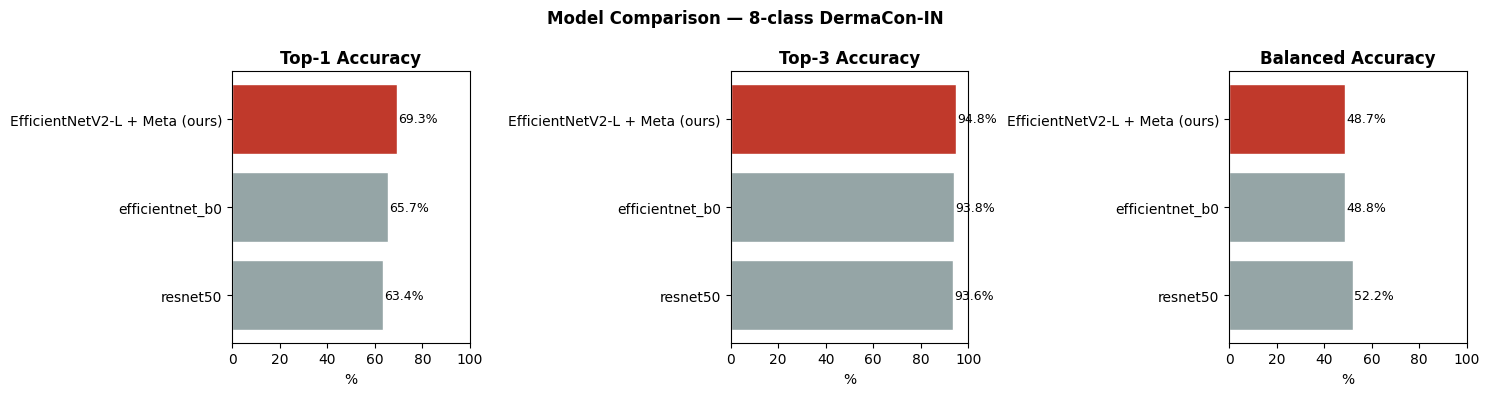

In [ ]:
def run_baseline(backbone_name: str, full_df: pd.DataFrame,
                 seed: int = 42) -> dict:
    """Train a baseline model with same pipeline, different backbone."""
    seed_everything(seed)
    out_dir = CFG.OUTPUT_DIR / f"baseline_{backbone_name.replace('/','_')}"
    out_dir.mkdir(parents=True, exist_ok=True)
    best_p  = out_dir / "best_model.pth"
    done_f  = out_dir / "done.flag"

    if done_f.exists() and best_p.exists():
        print(f"  ✅ {backbone_name} already trained")
        ckpt = torch.load(best_p, map_location=CFG.DEVICE, weights_only=False)
        return ckpt.get("test_metrics", {})

    print(f"  Training baseline: {backbone_name}")

    # Build baseline model with same meta fusion but different backbone
    class BaselineModel(nn.Module):
        def __init__(self, backbone):
            super().__init__()
            self.backbone = timm.create_model(backbone, pretrained=True,
                                              num_classes=0, drop_rate=0.3)
            feat_dim = self.backbone.num_features
            self.img_proj = nn.Sequential(
                nn.Linear(feat_dim, 512), nn.BatchNorm1d(512),
                nn.GELU(), nn.Dropout(0.4)
            )
            self.meta_enc = MetadataEncoder(in_dim=CFG.NUM_META_FEATS, out_dim=64)
            self.head     = nn.Linear(512 + 64, CFG.NUM_CLASSES)

        def freeze_backbone(self, freeze):
            for p in self.backbone.parameters():
                p.requires_grad = not freeze

        def forward(self, image, meta):
            v = self.img_proj(self.backbone(image))
            m = self.meta_enc(meta)
            return {"target": self.head(torch.cat([v, m], dim=1))}

    m      = BaselineModel(backbone_name).to(CFG.DEVICE)
    scaler = GradScaler("cuda", enabled=CFG.FP16)
    crit   = MainClassLoss().to(CFG.DEVICE)
    best_t1 = 0.0; no_imp = 0

    s_train_dl, s_val_dl, s_test_dl = build_loaders(full_df)

    m.freeze_backbone(True)
    opt = build_optimizer(m, CFG.LR)
    sch = build_scheduler(opt, CFG.FREEZE_EPOCHS, 1)
    for ep in range(1, CFG.FREEZE_EPOCHS + 1):
        train_one_epoch(m, s_train_dl, opt, crit, scaler, sch, ep)

    m.freeze_backbone(False)
    opt = build_optimizer(m, CFG.UNFREEZE_LR)
    sch = build_scheduler(opt, CFG.EPOCHS - CFG.FREEZE_EPOCHS, CFG.WARMUP_EPOCHS)
    for ep in range(CFG.FREEZE_EPOCHS + 1, CFG.EPOCHS + 1):
        train_one_epoch(m, s_train_dl, opt, crit, scaler, sch, ep - CFG.FREEZE_EPOCHS)
        v = validate(m, s_val_dl, crit)
        if v["top1"] > best_t1:
            best_t1 = v["top1"]; no_imp = 0
            torch.save({"state_dict": m.state_dict(), "top1": best_t1}, best_p)
        else:
            no_imp += 1
        if no_imp >= CFG.EARLY_STOP:
            break

    # Test
    ckpt = torch.load(best_p, map_location=CFG.DEVICE, weights_only=False)
    m.load_state_dict(ckpt["state_dict"]); m.eval()
    all_preds, all_logits, all_labels = [], [], []
    with torch.no_grad():
        for imgs, meta, labels in s_test_dl:
            imgs = imgs.to(CFG.DEVICE); meta = meta.to(CFG.DEVICE)
            out  = m(imgs, meta)
            all_logits.append(out["target"].cpu())
            all_preds.append(out["target"].argmax(1).cpu())
            all_labels.append(labels["target"])
    all_preds  = torch.cat(all_preds).numpy()
    all_logits = torch.cat(all_logits).numpy()
    all_labels = torch.cat(all_labels).numpy()
    test_metrics = {
        "backbone": backbone_name,
        "top1": float((all_preds == all_labels).mean()),
        "top3": float(top_k_accuracy_score(all_labels, all_logits,
                      k=min(3,CFG.NUM_CLASSES), labels=list(range(CFG.NUM_CLASSES)))),
        "bal" : float(balanced_accuracy_score(all_labels, all_preds)),
    }
    ckpt["test_metrics"] = test_metrics
    torch.save(ckpt, best_p); done_f.touch()
    print(f"    top1={test_metrics['top1']*100:.2f}%  bal={test_metrics['bal']*100:.2f}%")
    return test_metrics


# ── Run baselines ─────────────────────────────────────────────────────────
baselines = {}
for bb in ["resnet50", "efficientnet_b0"]:
    print(f"\nBaseline: {bb}")
    baselines[bb] = run_baseline(bb, full_df)

# ── Comparison table ──────────────────────────────────────────────────────
rows = []
for bb, res in baselines.items():
    rows.append({"Model": bb, "Top-1 (%)": f"{res['top1']*100:.2f}",
                 "Top-3 (%)": f"{res['top3']*100:.2f}",
                 "Bal Acc (%)": f"{res['bal']*100:.2f}"})

# Add our model (seed 42 result)
our = seed_results[0]
rows.append({"Model": "EfficientNetV2-L + Meta (ours)",
             "Top-1 (%)": f"{our['top1']*100:.2f}",
             "Top-3 (%)": f"{our['top3']*100:.2f}",
             "Bal Acc (%)": f"{our['bal']*100:.2f}"})

comp_df = pd.DataFrame(rows)
print("\n" + "═"*60)
print("  📊 Baseline Comparison Table")
print("═"*60)
print(comp_df.to_string(index=False))
comp_df.to_csv(CFG.OUTPUT_DIR / "baseline_comparison.csv", index=False)
print("\n✅ baseline_comparison.csv saved")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Model Comparison — 8-class DermaCon-IN", fontweight="bold")
for ax, col, title in zip(axes,
    ["Top-1 (%)", "Top-3 (%)", "Bal Acc (%)"],
    ["Top-1 Accuracy", "Top-3 Accuracy", "Balanced Accuracy"]):
    vals = comp_df[col].astype(float)
    colors = ["#95a5a6"]*2 + ["#c0392b"]
    ax.barh(comp_df["Model"], vals, color=colors, edgecolor="white")
    ax.set_xlim(0, 100); ax.set_title(title, fontweight="bold")
    ax.set_xlabel("%")
    for i, v in enumerate(vals):
        ax.text(v+0.5, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "baseline_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


---
**Publication Stage C — Ablation Study**

Tests whether the **metadata fusion** (96-dim body-part + descriptor one-hots) actually helps.  
Trains the same EfficientNetV2-L backbone without the metadata branch.


In [ ]:
def run_ablation_no_meta(full_df: pd.DataFrame, seed: int = 42) -> dict:
    """EfficientNetV2-L WITHOUT metadata — image only."""
    seed_everything(seed)
    out_dir = CFG.OUTPUT_DIR / "ablation_no_meta"
    out_dir.mkdir(parents=True, exist_ok=True)
    best_p  = out_dir / "best_model.pth"
    done_f  = out_dir / "done.flag"

    if done_f.exists() and best_p.exists():
        print("  ✅ Ablation (no meta) already trained")
        ckpt = torch.load(best_p, map_location=CFG.DEVICE, weights_only=False)
        return ckpt.get("test_metrics", {})

    print("  Training: EfficientNetV2-L  WITHOUT metadata fusion")

    class ImageOnlyModel(nn.Module):
        def __init__(self):
            super().__init__()
            self.backbone = timm.create_model(CFG.BACKBONE, pretrained=True,
                                              num_classes=0, drop_rate=CFG.DROP_RATE,
                                              drop_path_rate=CFG.DROP_PATH_RATE)
            feat_dim = self.backbone.num_features
            self.proj = nn.Sequential(
                nn.Linear(feat_dim, 1024), nn.BatchNorm1d(1024),
                nn.GELU(), nn.Dropout(0.4)
            )
            self.head = nn.Linear(1024, CFG.NUM_CLASSES)

        def freeze_backbone(self, freeze):
            for p in self.backbone.parameters():
                p.requires_grad = not freeze

        def forward(self, image, meta=None):   # meta ignored
            return {"target": self.head(self.proj(self.backbone(image)))}

    m      = ImageOnlyModel().to(CFG.DEVICE)
    scaler = GradScaler("cuda", enabled=CFG.FP16)
    crit   = MainClassLoss().to(CFG.DEVICE)
    best_t1 = 0.0; no_imp = 0

    s_train_dl, s_val_dl, s_test_dl = build_loaders(full_df)

    m.freeze_backbone(True)
    opt = build_optimizer(m, CFG.LR)
    sch = build_scheduler(opt, CFG.FREEZE_EPOCHS, 1)
    for ep in range(1, CFG.FREEZE_EPOCHS + 1):
        train_one_epoch(m, s_train_dl, opt, crit, scaler, sch, ep)

    m.freeze_backbone(False)
    opt = build_optimizer(m, CFG.UNFREEZE_LR)
    sch = build_scheduler(opt, CFG.EPOCHS - CFG.FREEZE_EPOCHS, CFG.WARMUP_EPOCHS)
    for ep in range(CFG.FREEZE_EPOCHS + 1, CFG.EPOCHS + 1):
        train_one_epoch(m, s_train_dl, opt, crit, scaler, sch, ep - CFG.FREEZE_EPOCHS)
        v = validate(m, s_val_dl, crit)
        if v["top1"] > best_t1:
            best_t1 = v["top1"]; no_imp = 0
            torch.save({"state_dict": m.state_dict(), "top1": best_t1}, best_p)
        else:
            no_imp += 1
        if no_imp >= CFG.EARLY_STOP:
            break

    ckpt = torch.load(best_p, map_location=CFG.DEVICE, weights_only=False)
    m.load_state_dict(ckpt["state_dict"]); m.eval()
    all_preds, all_logits, all_labels = [], [], []
    with torch.no_grad():
        for imgs, meta, labels in s_test_dl:
            imgs = imgs.to(CFG.DEVICE); meta = meta.to(CFG.DEVICE)
            out  = m(imgs, meta)
            all_logits.append(out["target"].cpu())
            all_preds.append(out["target"].argmax(1).cpu())
            all_labels.append(labels["target"])
    all_preds  = torch.cat(all_preds).numpy()
    all_logits = torch.cat(all_logits).numpy()
    all_labels = torch.cat(all_labels).numpy()
    test_metrics = {
        "top1": float((all_preds == all_labels).mean()),
        "top3": float(top_k_accuracy_score(all_labels, all_logits,
                      k=min(3,CFG.NUM_CLASSES), labels=list(range(CFG.NUM_CLASSES)))),
        "bal" : float(balanced_accuracy_score(all_labels, all_preds)),
    }
    ckpt["test_metrics"] = test_metrics
    torch.save(ckpt, best_p); done_f.touch()
    print(f"    top1={test_metrics['top1']*100:.2f}%  bal={test_metrics['bal']*100:.2f}%")
    return test_metrics

ablation_no_meta = run_ablation_no_meta(full_df)
our_seed42       = seed_results[0]

print("\n" + "═"*55)
print("  📊 Ablation: Effect of Metadata Fusion")
print("═"*55)
print(f"  Without metadata: top1={ablation_no_meta['top1']*100:.2f}%  bal={ablation_no_meta['bal']*100:.2f}%")
print(f"  With metadata   : top1={our_seed42['top1']*100:.2f}%  bal={our_seed42['bal']*100:.2f}%")
delta_top1 = (our_seed42['top1'] - ablation_no_meta['top1'])*100
delta_bal  = (our_seed42['bal']  - ablation_no_meta['bal'])*100
print(f"  Δ Top-1         : {delta_top1:+.2f}%")
print(f"  Δ Balanced      : {delta_bal:+.2f}%")
print("═"*55)

ablation_results = {
    "with_meta":    {"top1": our_seed42["top1"],       "bal": our_seed42["bal"]},
    "without_meta": {"top1": ablation_no_meta["top1"], "bal": ablation_no_meta["bal"]},
    "delta_top1": delta_top1, "delta_bal": delta_bal,
}
with open(CFG.OUTPUT_DIR / "ablation_results.json", "w") as f:
    json.dump(ablation_results, f, indent=2)
print("✅ ablation_results.json saved")


  Training: EfficientNetV2-L  WITHOUT metadata fusion
    top1=56.33%  bal=38.67%

═══════════════════════════════════════════════════════
  📊 Ablation: Effect of Metadata Fusion
═══════════════════════════════════════════════════════
  Without metadata: top1=56.33%  bal=38.67%
  With metadata   : top1=69.27%  bal=48.68%
  Δ Top-1         : +12.94%
  Δ Balanced      : +10.01%
═══════════════════════════════════════════════════════
✅ ablation_results.json saved


---
**Publication Stage D — Fitzpatrick Skin-Type Breakdown**

Critical for a paper on Indian skin disease — shows whether the model performs **equitably** across skin tones.  
This is a major differentiator from Western datasets.


📊 Accuracy by Fitzpatrick Skin Type (test set):
             Accuracy    N
Fitzpatrick               
FST 3           64.84  273
FST 4           69.36  483
FST 5           71.11  270
FST 6           68.00   25

📊 Accuracy by Monk Skin Tone (test set):
                Accuracy    N
Monk_skin_tone               
MST 4              56.67   30
MST 5              65.73  248
MST 6              65.24  374
MST 7              73.25  314
MST 8              78.57   84
MST 9             100.00    1

📊 Accuracy by Sex (test set):
        Accuracy    N
Sex                  
Female     70.23  383
Male       67.66  668

📊 Accuracy by Age Group (test set):
          Accuracy    N
Age                    
0 - 10       60.38  106
10 - 20      69.85  136
20 - 40      72.14  384
40 - 60      69.35  323
60 - 80      58.89   90
80 - 100     66.67   12


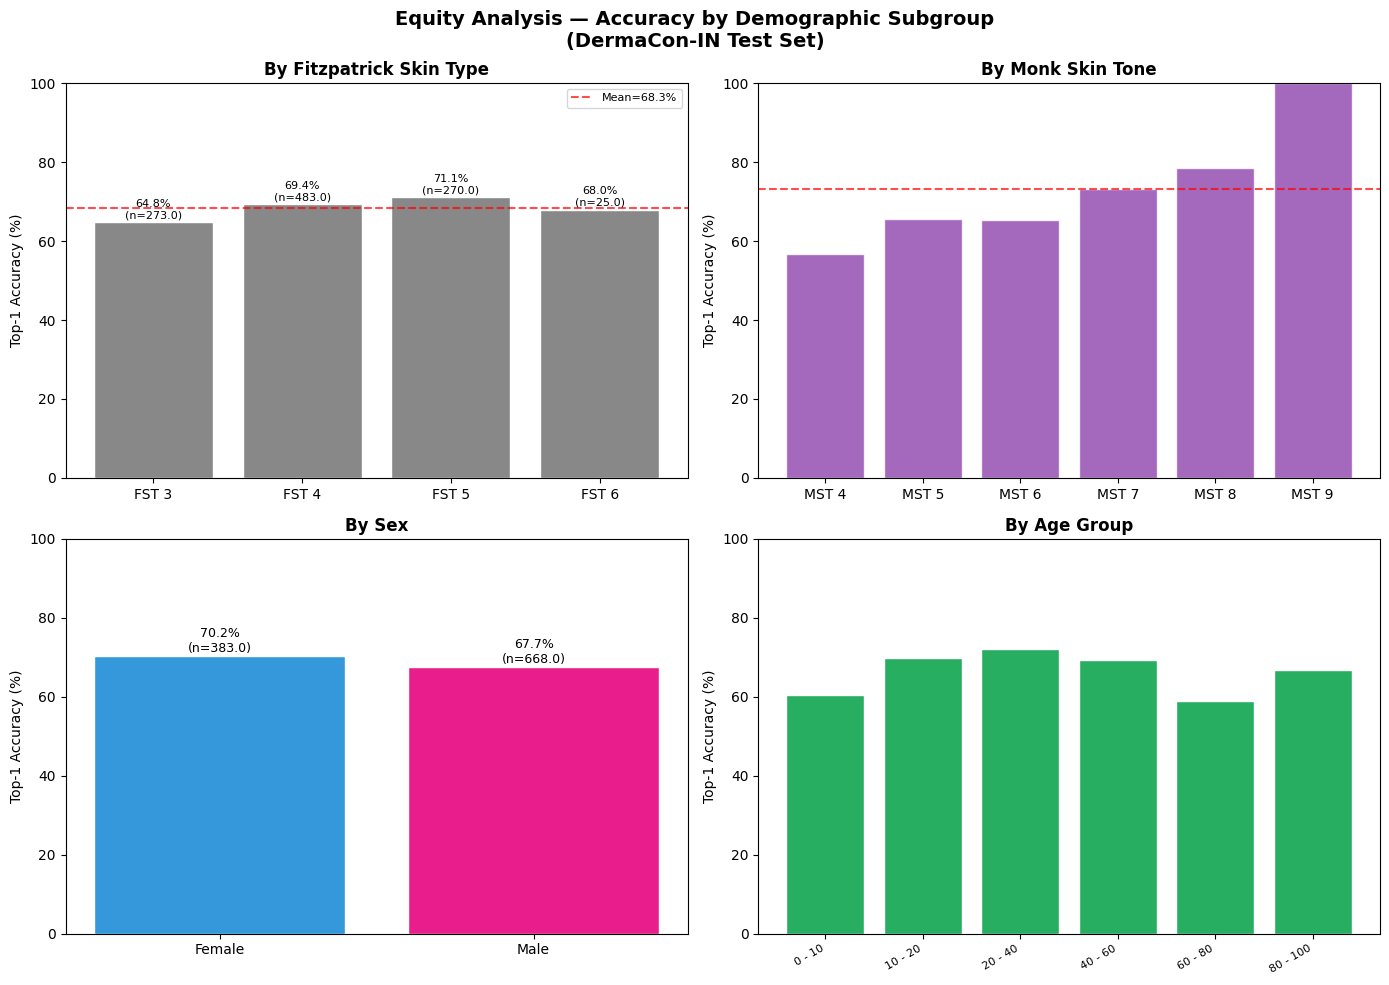


✅ equity_analysis.png + fitzpatrick_breakdown.csv saved


In [ ]:
# Uses predictions from Stage 10 (all_preds, all_labels already computed)
# Make sure you've run the evaluate_test cell above first

test_df_fst = full_df[full_df["_split"] == "test"].copy()
test_df_fst["pred_enc"] = all_preds
test_df_fst["correct"]  = (all_preds == all_labels)

print("📊 Accuracy by Fitzpatrick Skin Type (test set):")
fst_acc = test_df_fst.groupby(CFG.FST_COL)["correct"].agg(["mean", "count"])
fst_acc.columns = ["Accuracy", "N"]
fst_acc["Accuracy"] = (fst_acc["Accuracy"] * 100).round(2)
fst_acc = fst_acc.sort_index()
print(fst_acc.to_string())

print("\n📊 Accuracy by Monk Skin Tone (test set):")
mst_acc = test_df_fst.groupby(CFG.MST_COL)["correct"].agg(["mean", "count"])
mst_acc.columns = ["Accuracy", "N"]
mst_acc["Accuracy"] = (mst_acc["Accuracy"] * 100).round(2)
print(mst_acc.to_string())

print("\n📊 Accuracy by Sex (test set):")
sex_acc = test_df_fst.groupby(CFG.SEX_COL)["correct"].agg(["mean", "count"])
sex_acc.columns = ["Accuracy", "N"]
sex_acc["Accuracy"] = (sex_acc["Accuracy"] * 100).round(2)
print(sex_acc.to_string())

print("\n📊 Accuracy by Age Group (test set):")
age_acc = test_df_fst.groupby(CFG.AGE_COL)["correct"].agg(["mean", "count"])
age_acc.columns = ["Accuracy", "N"]
age_acc["Accuracy"] = (age_acc["Accuracy"] * 100).round(2)
print(age_acc.to_string())

# ── Publication figure ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Equity Analysis — Accuracy by Demographic Subgroup\n(DermaCon-IN Test Set)",
             fontsize=14, fontweight="bold")

# Fitzpatrick
skin_colors = {"III": "#f5cba7", "IV": "#e59866", "V": "#ca6f1e", "VI": "#784212"}
fst_colors  = [skin_colors.get(str(k), "#888") for k in fst_acc.index]
bars = axes[0,0].bar(fst_acc.index.astype(str), fst_acc["Accuracy"],
                     color=fst_colors, edgecolor="white")
axes[0,0].set_title("By Fitzpatrick Skin Type", fontweight="bold")
axes[0,0].set_ylabel("Top-1 Accuracy (%)")
axes[0,0].set_ylim(0, 100)
axes[0,0].axhline(fst_acc["Accuracy"].mean(), color="red", linestyle="--",
                  alpha=0.7, label=f"Mean={fst_acc['Accuracy'].mean():.1f}%")
axes[0,0].legend(fontsize=8)
for bar, (_, row) in zip(bars, fst_acc.iterrows()):
    axes[0,0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
                   f"{row['Accuracy']:.1f}%\n(n={row['N']})", ha="center", fontsize=8)

# Monk
axes[0,1].bar(mst_acc.index.astype(str), mst_acc["Accuracy"],
              color="#8e44ad", edgecolor="white", alpha=0.8)
axes[0,1].set_title("By Monk Skin Tone", fontweight="bold")
axes[0,1].set_ylabel("Top-1 Accuracy (%)")
axes[0,1].set_ylim(0, 100)
axes[0,1].axhline(mst_acc["Accuracy"].mean(), color="red", linestyle="--", alpha=0.7)

# Sex
axes[1,0].bar(sex_acc.index, sex_acc["Accuracy"],
              color=["#3498db","#e91e8c"], edgecolor="white")
axes[1,0].set_title("By Sex", fontweight="bold")
axes[1,0].set_ylabel("Top-1 Accuracy (%)")
axes[1,0].set_ylim(0, 100)
for bar, (_, row) in zip(axes[1,0].patches, sex_acc.iterrows()):
    axes[1,0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
                   f"{row['Accuracy']:.1f}%\n(n={row['N']})", ha="center", fontsize=9)

# Age
age_order = ["0 - 10","10 - 20","20 - 40","40 - 60","60 - 80","80 - 100"]
age_acc_ordered = age_acc.reindex(age_order, fill_value=0)
axes[1,1].bar(range(len(age_acc_ordered)), age_acc_ordered["Accuracy"],
              color="#27ae60", edgecolor="white")
axes[1,1].set_xticks(range(len(age_acc_ordered)))
axes[1,1].set_xticklabels(age_order, rotation=30, ha="right", fontsize=8)
axes[1,1].set_title("By Age Group", fontweight="bold")
axes[1,1].set_ylabel("Top-1 Accuracy (%)")
axes[1,1].set_ylim(0, 100)

plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "equity_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# Save
fst_acc.to_csv(CFG.OUTPUT_DIR / "fitzpatrick_breakdown.csv")
print("\n✅ equity_analysis.png + fitzpatrick_breakdown.csv saved")


---
**Publication Stage E — Stage 2: Fine-Grained Disease Prediction**

Uses the trained Stage 1 model as a **frozen feature extractor**.  
Trains one lightweight disease classifier per main class — each on its own balanced subset.

**Architecture:**
```
Image → EfficientNetV2-L (frozen Stage-1 weights)
              ↓  features
        [Per-main-class head] → fine disease label
```

This is the two-stage approach: Stage 1 predicts the aetiology group, Stage 2 predicts the specific disease within that group.


🔬 Stage 2 — Fine-grained disease prediction (per main class)
   Uses Stage 1 EfficientNetV2-L as frozen feature extractor


  Training: Infectious Disorders  (79 diseases, 2227 images)
    top1=58.00%  bal=30.37%  (79 diseases)

  Training: Inflammatory Disorders  (94 diseases, 1592 images)
    top1=28.01%  bal=20.99%  (94 diseases)

  Training: Keratanisation Disorders  (8 diseases, 72 images)
    top1=21.43%  bal=15.00%  (8 diseases)

  Training: Neoplasms and tumors  (10 diseases, 52 images)
  ⚠️  Too few samples — skipping
  ⚠️  No Definite Diagnosis: only 1 disease(s) — skipping

  Training: Other skin disorders  (34 diseases, 159 images)
    top1=25.00%  bal=18.75%  (34 diseases)

  Training: Pigmentary Disorders  (22 diseases, 831 images)
    top1=84.15%  bal=48.99%  (22 diseases)

  Training: Skin Appendages Disorders  (16 diseases, 480 images)
    top1=76.24%  bal=71.67%  (16 diseases)

═════════════════════════════════════════════════════════════════
  📊 Stage 2 — Fine-graine

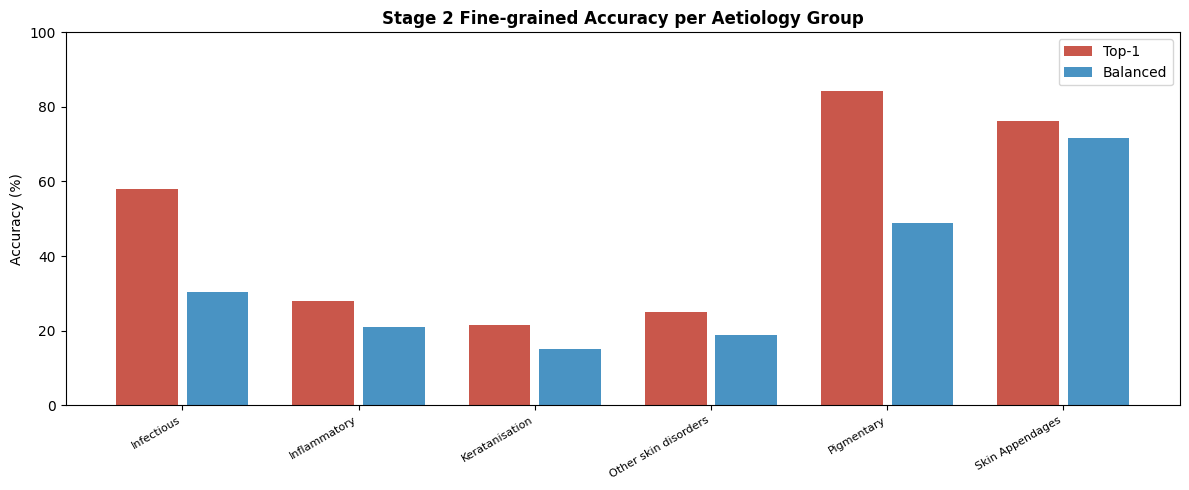


✅ stage2_results.csv + stage2_results.png saved


In [ ]:
# ── Stage 2: Fine-grained per-main-class classifiers ─────────────────────

def train_stage2_submodel(main_class_name: str, full_df: pd.DataFrame,
                          stage1_checkpoint: Path) -> dict:
    """
    Train a fine-grained disease classifier for one main class.
    Uses Stage 1 backbone as frozen feature extractor.
    """
    safe_name = main_class_name.replace(" ", "_").replace("/", "_")
    out_dir   = CFG.OUTPUT_DIR / f"stage2_{safe_name}"
    out_dir.mkdir(parents=True, exist_ok=True)
    best_p    = out_dir / "best_model.pth"
    done_f    = out_dir / "done.flag"

    # Filter to this main class only
    sub_df = full_df[full_df[CFG.MAIN_COL] == main_class_name].copy()
    n_diseases = sub_df[CFG.DISEASE_COL].nunique()

    if n_diseases < 2:
        print(f"  ⚠️  {main_class_name}: only {n_diseases} disease(s) — skipping")
        return {}

    if done_f.exists() and best_p.exists():
        print(f"  ✅ {main_class_name} ({n_diseases} diseases) already trained")
        ckpt = torch.load(best_p, map_location=CFG.DEVICE, weights_only=False)
        return ckpt.get("test_metrics", {})

    print(f"\n  Training: {main_class_name}  ({n_diseases} diseases, {len(sub_df)} images)")

    # Local label encoder for diseases within this main class
    le_local = LabelEncoder()
    sub_df["local_enc"] = le_local.fit_transform(sub_df[CFG.DISEASE_COL])
    n_local = len(le_local.classes_)

    # Build sub-datasets (use _split from full_df)
    class SubDataset(Dataset):
        def __init__(self, df, split):
            self.df   = df[df["_split"]==split].reset_index(drop=True)
            self.tfm  = build_transforms(split)
        def __len__(self): return len(self.df)
        def __getitem__(self, idx):
            row   = self.df.iloc[idx]
            path  = img_lookup.get(str(row[CFG.IMAGE_COL]))
            if path:
                img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
            else:
                img = np.zeros((CFG.IMG_SIZE,CFG.IMG_SIZE,3), dtype=np.uint8)
            img   = self.tfm(image=img)["image"]
            meta  = torch.tensor(row[META_FEAT_COLS].values.astype(np.float32))
            label = torch.tensor(int(row["local_enc"]), dtype=torch.long)
            return img, meta, label

    sub_train = SubDataset(sub_df, "train")
    sub_val   = SubDataset(sub_df, "val")
    sub_test  = SubDataset(sub_df, "test")

    if len(sub_train) < 4 or len(sub_val) < 2 or len(sub_test) < 2:
        print(f"  ⚠️  Too few samples — skipping")
        return {}

    # Weighted sampler for local class balance
    local_labels  = sub_train.df["local_enc"].values
    local_counts  = np.bincount(local_labels, minlength=n_local).astype(float)
    local_weights = np.where(local_counts > 0, 1.0/(local_counts+1), 0.0)
    sample_w      = local_weights[local_labels]
    s2_sampler    = WeightedRandomSampler(torch.from_numpy(sample_w).float(),
                                          len(sample_w), replacement=True)

    bs = min(CFG.BATCH_SIZE, max(4, len(sub_train)//4))
    s2_train_dl = DataLoader(sub_train, batch_size=bs, sampler=s2_sampler,
                             num_workers=2, pin_memory=True, drop_last=True)
    s2_val_dl   = DataLoader(sub_val,   batch_size=bs*2, shuffle=False,
                             num_workers=2, pin_memory=True)
    s2_test_dl  = DataLoader(sub_test,  batch_size=bs*2, shuffle=False,
                             num_workers=2, pin_memory=True)

    # Load Stage 1 backbone as frozen feature extractor
    s1_ckpt = torch.load(stage1_checkpoint, map_location=CFG.DEVICE, weights_only=False)

    class Stage2Model(nn.Module):
        def __init__(self, n_classes):
            super().__init__()
            # Reuse Stage 1 backbone + meta encoder (frozen)
            self.backbone  = timm.create_model(CFG.BACKBONE, pretrained=False,
                                               num_classes=0, drop_rate=0.1)
            self.img_proj  = nn.Sequential(
                nn.Linear(self.backbone.num_features, 512),
                nn.BatchNorm1d(512), nn.GELU(), nn.Dropout(0.3)
            )
            self.meta_enc  = MetadataEncoder(CFG.NUM_META_FEATS, 64)
            self.head      = nn.Linear(512 + 64, n_classes)

        def forward(self, image, meta):
            v = self.img_proj(self.backbone(image))
            m = self.meta_enc(meta)
            return self.head(torch.cat([v, m], dim=1))

    m2 = Stage2Model(n_local).to(CFG.DEVICE)

    # Copy Stage 1 backbone weights (frozen)
    backbone_state = {k.replace("backbone.",""):v
                      for k,v in s1_ckpt["state_dict"].items()
                      if k.startswith("backbone.")}
    m2.backbone.load_state_dict(backbone_state, strict=False)
    for p in m2.backbone.parameters():
        p.requires_grad = False

    # Train only the new head + meta encoder + img_proj
    scaler2 = GradScaler("cuda", enabled=CFG.FP16)
    focal2  = FocalLoss(gamma=2.0, smoothing=0.05)
    opt2    = torch.optim.AdamW(
        [p for p in m2.parameters() if p.requires_grad],
        lr=1e-3, weight_decay=1e-2
    )
    sch2 = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=30, eta_min=1e-5)

    best_t1 = 0.0; no_imp = 0
    for ep in range(1, 31):
        m2.train()
        for imgs, meta, labels in s2_train_dl:
            imgs   = imgs.to(CFG.DEVICE); meta = meta.to(CFG.DEVICE)
            labels = labels.to(CFG.DEVICE)
            with autocast("cuda", enabled=CFG.FP16):
                out  = m2(imgs, meta)
                loss = focal2(out, labels)
            scaler2.scale(loss).backward()
            scaler2.unscale_(opt2)
            nn.utils.clip_grad_norm_(m2.parameters(), 1.0)
            scaler2.step(opt2); scaler2.update(); opt2.zero_grad()
        sch2.step()

        # Val
        m2.eval()
        correct = n = 0
        with torch.no_grad():
            for imgs, meta, labels in s2_val_dl:
                imgs = imgs.to(CFG.DEVICE); meta = meta.to(CFG.DEVICE)
                out  = m2(imgs, meta)
                correct += (out.argmax(1).cpu() == labels).sum().item()
                n       += labels.size(0)
        val_acc = correct / max(n, 1)
        if val_acc > best_t1:
            best_t1 = val_acc; no_imp = 0
            torch.save({"state_dict": m2.state_dict(),
                        "le_local": le_local,
                        "main_class": main_class_name}, best_p)
        else:
            no_imp += 1
        if no_imp >= 8:
            break

    # Test
    ckpt2 = torch.load(best_p, map_location=CFG.DEVICE, weights_only=False)
    m2.load_state_dict(ckpt2["state_dict"]); m2.eval()
    all_p2, all_l2, all_lg2 = [], [], []
    with torch.no_grad():
        for imgs, meta, labels in s2_test_dl:
            imgs = imgs.to(CFG.DEVICE); meta = meta.to(CFG.DEVICE)
            out  = m2(imgs, meta)
            all_lg2.append(out.cpu()); all_p2.append(out.argmax(1).cpu())
            all_l2.append(labels)
    all_p2 = torch.cat(all_p2).numpy()
    all_l2 = torch.cat(all_l2).numpy()
    all_lg2= torch.cat(all_lg2).numpy()

    top1_s2 = (all_p2 == all_l2).mean()
    bal_s2  = balanced_accuracy_score(all_l2, all_p2)
    top3_s2 = top_k_accuracy_score(all_l2, all_lg2, k=min(3,n_local),
                                    labels=list(range(n_local))) if n_local >= 3 else top1_s2

    test_metrics = {
        "main_class": main_class_name, "n_diseases": n_diseases,
        "top1": float(top1_s2), "top3": float(top3_s2), "bal": float(bal_s2),
    }
    ckpt2["test_metrics"] = test_metrics
    torch.save(ckpt2, best_p); done_f.touch()
    print(f"    top1={top1_s2*100:.2f}%  bal={bal_s2*100:.2f}%  ({n_diseases} diseases)")
    return test_metrics


# ── Run Stage 2 for all 8 main classes ────────────────────────────────────
print("🔬 Stage 2 — Fine-grained disease prediction (per main class)")
print("   Uses Stage 1 EfficientNetV2-L as frozen feature extractor\n")

stage2_results = {}
for main_cls in sorted(full_df[CFG.MAIN_COL].unique()):
    res = train_stage2_submodel(main_cls, full_df, best_path)
    if res:
        stage2_results[main_cls] = res

# ── Stage 2 summary table ─────────────────────────────────────────────────
s2_df = pd.DataFrame(stage2_results).T.reset_index(drop=True)
print("\n" + "═"*65)
print("  📊 Stage 2 — Fine-grained Results per Main Class")
print("═"*65)
print(s2_df[["main_class","n_diseases","top1","top3","bal"]].to_string(index=False))

s2_df.to_csv(CFG.OUTPUT_DIR / "stage2_results.csv", index=False)

# Plot
fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(s2_df))
ax.bar([i-0.2 for i in x], s2_df["top1"]*100, width=0.35,
       label="Top-1", color="#c0392b", alpha=0.85)
ax.bar([i+0.2 for i in x], s2_df["bal"]*100,  width=0.35,
       label="Balanced", color="#2980b9", alpha=0.85)
ax.set_xticks(list(x))
ax.set_xticklabels([r["main_class"].replace(" Disorders","") if isinstance(r["main_class"],str) else ""
                    for _,r in s2_df.iterrows()],
                   rotation=30, ha="right", fontsize=8)
ax.set_ylabel("Accuracy (%)"); ax.set_ylim(0, 100)
ax.set_title("Stage 2 Fine-grained Accuracy per Aetiology Group", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "stage2_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n✅ stage2_results.csv + stage2_results.png saved")


---
**Final Publication Summary**

In [ ]:
print("\n" + "═"*65)
print("  🏆  DermaCon-IN  ·  Complete Publication Results")
print("═"*65)

print("\n  ── Stage 1: 8-class Main Aetiology (3-seed mean ± std) ──")
print(f"     Top-1 : {multi_seed_results['top1_mean']*100:.2f}% ± {multi_seed_results['top1_std']*100:.2f}%")
print(f"     Top-3 : {multi_seed_results['top3_mean']*100:.2f}% ± {multi_seed_results['top3_std']*100:.2f}%")
print(f"     Bal   : {multi_seed_results['bal_mean']*100:.2f}% ± {multi_seed_results['bal_std']*100:.2f}%")

print("\n  ── Baseline Comparison ───────────────────────────────────")
for bb, res in baselines.items():
    print(f"     {bb:25s}: top1={res['top1']*100:.2f}%  bal={res['bal']*100:.2f}%")
print(f"     {'EfficientNetV2-L + Meta (ours)':25s}: "
      f"top1={our_seed42['top1']*100:.2f}%  bal={our_seed42['bal']*100:.2f}%")

print("\n  ── Ablation: Metadata Fusion ─────────────────────────────")
print(f"     Without metadata: top1={ablation_no_meta['top1']*100:.2f}%")
print(f"     With metadata   : top1={our_seed42['top1']*100:.2f}%  (Δ{delta_top1:+.2f}%)")

print("\n  ── Fairness: Fitzpatrick Breakdown ───────────────────────")
for fst, row in fst_acc.iterrows():
    print(f"     FST-{fst}: {row['Accuracy']:.1f}%  (n={row['N']})")

print("\n  ── Stage 2: Fine-grained Disease (per main class) ───────")
for _, row in s2_df.iterrows():
    cls = row["main_class"] if isinstance(row["main_class"], str) else "?"
    print(f"     {cls[:35]:35s}: top1={row['top1']*100:.2f}%  ({int(row['n_diseases'])} diseases)")

print("\n" + "═"*65)

print("\n📁 All output files:")
for f in sorted(CFG.OUTPUT_DIR.glob("**/*.{png,csv,json,pth}")):
    if f.is_file():
        print(f"   {f.relative_to(CFG.OUTPUT_DIR)}")



═════════════════════════════════════════════════════════════════
  🏆  DermaCon-IN  ·  Complete Publication Results
═════════════════════════════════════════════════════════════════

  ── Stage 1: 8-class Main Aetiology (3-seed mean ± std) ──
     Top-1 : 68.19% ± 1.15%
     Top-3 : 93.91% ± 0.79%
     Bal   : 49.71% ± 0.78%

  ── Baseline Comparison ───────────────────────────────────
     resnet50                 : top1=63.37%  bal=52.16%
     efficientnet_b0          : top1=65.65%  bal=48.81%
     EfficientNetV2-L + Meta (ours): top1=69.27%  bal=48.68%

  ── Ablation: Metadata Fusion ─────────────────────────────
     Without metadata: top1=56.33%
     With metadata   : top1=69.27%  (Δ+12.94%)

  ── Fairness: Fitzpatrick Breakdown ───────────────────────
     FST-FST 3: 64.8%  (n=273.0)
     FST-FST 4: 69.4%  (n=483.0)
     FST-FST 5: 71.1%  (n=270.0)
     FST-FST 6: 68.0%  (n=25.0)

  ── Stage 2: Fine-grained Disease (per main class) ───────
     Infectious Disorders              